# Лабораторная работа №2: классификация

Датасет: [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset) с Kaggle. По данным о пассажире нужно предсказать, выжил он (`Survived = 1`) или нет (`Survived = 0`).

Основная метрика — F1-score для класса `Survived = 1`, дополнительно считаю Accuracy, Precision, Recall (и ROC-AUC для справки). Порог по заданию: F1 > 0.70.

In [1]:
import os
# на Windows 11 без этого KNN печатает длинный traceback, когда joblib пытается посчитать ядра процессора
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set_theme(style="darkgrid")

RANDOM_STATE = 42

# Часть 1. Загружаем данные

Датасет скачан с Kaggle (`Titanic-Dataset.csv`) и лежит рядом с ноутбуком.

In [2]:
data = pd.read_csv("Titanic-Dataset.csv")

print(data.shape)
data.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Что означают колонки:

| Колонка | Описание |
|---|---|
| `PassengerId` | номер строки в датасете |
| `Survived` | целевая переменная: 1 — выжил, 0 — погиб |
| `Pclass` | класс билета (1 — первый, 3 — третий) |
| `Name` | имя пассажира, включая обращение (Mr, Mrs, Miss, Master, ...) |
| `Sex` | пол |
| `Age` | возраст |
| `SibSp` | число братьев/сестёр и супругов на борту |
| `Parch` | число родителей и детей на борту |
| `Ticket` | номер билета |
| `Fare` | стоимость билета |
| `Cabin` | номер каюты |
| `Embarked` | порт посадки (C — Шербур, Q — Квинстаун, S — Саутгемптон) |

In [4]:
missing = pd.DataFrame({"пропусков": data.isna().sum(), "доля": data.isna().mean().round(3)})
missing[missing["пропусков"] > 0]

,пропусков,доля
Age,177,0.199
Cabin,687,0.771
Embarked,2,0.002


Пропуски есть в трёх колонках, и обрабатывать их нужно по-разному:
- `Age` — нет у 20% пассажиров. Возраст важен (детей спасали в первую очередь), поэтому колонку оставляю и заполняю медианой. Медиана устойчива к выбросам и считается только по train (внутри пайплайна).
- `Cabin` — нет у 77% пассажиров. Восстановить её нечем, а заполнение чем-то одним превратит колонку почти в константу. К тому же сама колонка подозрительная (разберу в части 3), поэтому в модель её не беру.
- `Embarked` — пропуск всего у 2 пассажиров, заполняю самым частым портом.

In [5]:
print("Полных дубликатов строк:", data.duplicated().sum())
print("Дубликатов без PassengerId и Name:", data.drop(columns=["PassengerId", "Name"]).duplicated().sum())

data.nunique().sort_values(ascending=False)

Полных дубликатов строк: 0
Дубликатов без PassengerId и Name: 15


PassengerId    891
Name           891
Ticket         681
Fare           248
Cabin          147
Age             88
SibSp            7
Parch            7
Embarked         3
Pclass           3
Survived         2
Sex              2
dtype: int64

Полных дубликатов нет. 15 строк совпадают с другими во всём, кроме `PassengerId` и `Name` — это разные люди с одинаковыми характеристиками (например, попутчики по одному билету с неизвестным возрастом), удалять их не нужно.

По числу уникальных значений сразу видны признаки, которые **идентифицируют конкретного пассажира**, а не описывают его:
- `PassengerId` и `Name` уникальны для каждой строки. Если дать их модели, она может просто запомнить, кто выжил, и на новых пассажирах это не сработает. `PassengerId` к тому же — просто номер строки, смысла в нём нет.
- `Ticket` — 681 значение на 891 пассажира, т.е. почти уникален. Одинаковый билет бывает только у попутчиков (семьи, друзья, слуги), и через него модель может «подсмотреть» судьбу попутчиков из train — это утечка, а не закономерность.
- `Cabin` — 147 разных кают на 204 известных значения, тоже почти идентификатор.

Эти колонки в модель не беру. Из `Name` можно достать полезную и не идентифицирующую информацию (обращение), это сделаю ниже.

# Часть 2. Подготовка выборок

Как и в первой лабораторной, делю данные на train и test **до** исследовательского анализа: дальше все графики и выводы делаю только по train.

In [6]:
from sklearn.model_selection import train_test_split

y = data["Survived"]
X = data.drop(columns=["Survived"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
pd.DataFrame({
    "train, шт": y_train.value_counts(),
    "test, шт": y_test.value_counts(),
    "train, доля": y_train.value_counts(normalize=True),
    "test, доля": y_test.value_counts(normalize=True),
}).round(3)

Train: (712, 11)  Test: (179, 11)


,"train, шт","test, шт","train, доля","test, доля"
Survived,,,,
0,439,110,0.617,0.615
1,273,69,0.383,0.385


**Размер выборок.** 80% / 20%: 712 пассажиров в train и 179 в test. Данных мало, поэтому большую часть оставляю на обучение. `random_state=42` фиксирую, как и в первой лабораторной, чтобы разбиение воспроизводилось и все модели обучались и проверялись на одних и тех же объектах.

**Способ разбиения.** Стратифицированный по `Survived`: доля выживших в train и test одинаковая (38.3% и 38.5%), как и требует задание. Без стратификации на 179 объектах доля выживших в тесте могла бы заметно «уехать», и метрики зависели бы от удачи разбиения.

Тест маленький: в нём всего 69 выживших. Одна лишняя правильно найденная выжившая меняет Recall на ~0.015, а F1 — примерно на 0.01. Поэтому все решения (признаки, гиперпараметры, выбор лучшей модели) принимаю по кросс-валидации на train, а тест использую только в конце.

# Часть 3. Знакомство с данными

Весь анализ в этой части — только по обучающей выборке.

Survived
0    0.617
1    0.383
Name: proportion, dtype: float64

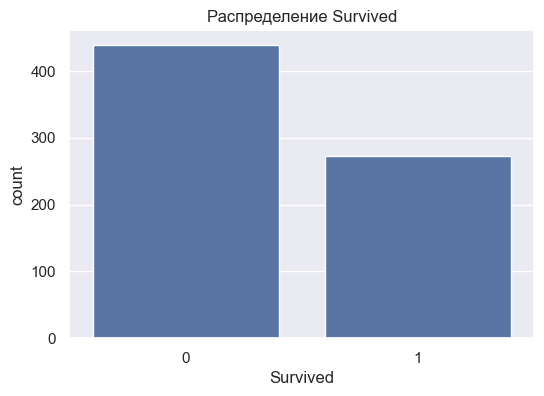

In [7]:
train = X_train.copy()
train["Survived"] = y_train

plot = sns.countplot(x=y_train, color="C0")
plot.figure.set_size_inches(6, 4)
plt.title("Распределение Survived")

y_train.value_counts(normalize=True).round(3)

Выводы: погибло 61.7% пассажиров, выжило 38.3%. Классы несбалансированы, хотя и не сильно. Из-за этого Accuracy — обманчивая метрика: модель, которая всем говорит «погиб», уже получит Accuracy ≈ 0.62, не найдя ни одного выжившего. Поэтому основная метрика — F1 для класса «выжил»: она равна нулю у такой модели и растёт, только если модель реально находит выживших и при этом не называет выжившими всех подряд.

         mean  size
Sex                
female  0.743   253
male    0.185   459 

         mean  size
Pclass             
1       0.649   171
2       0.447   150
3       0.243   391 

           mean  size
Embarked             
C         0.561   139
Q         0.436    55
S         0.328   516 



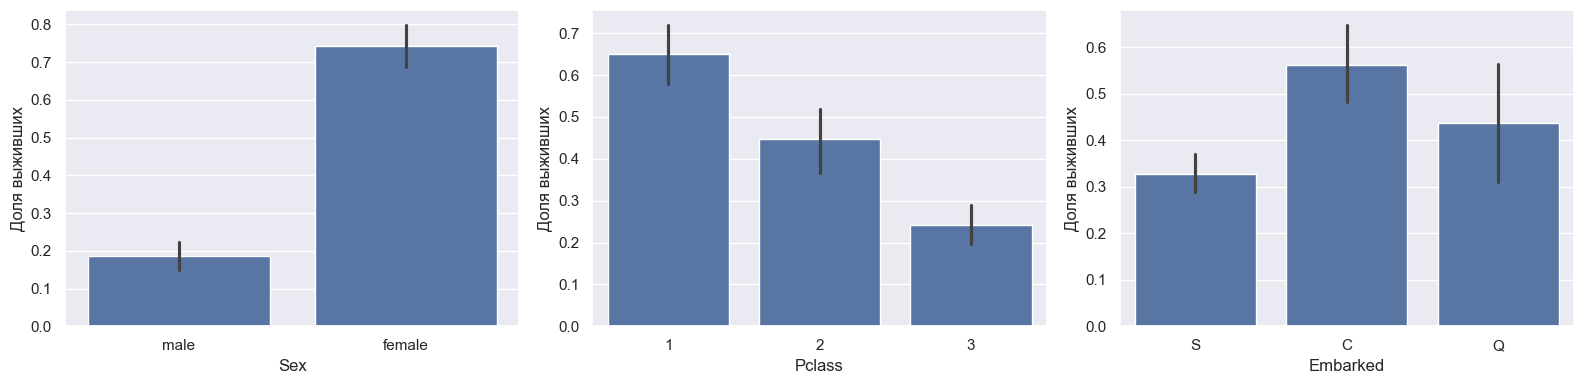

In [8]:
fig, axs = plt.subplots(figsize=(16, 4), ncols=3)
for i, feature in enumerate(["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=train, x=feature, y="Survived", color="C0", ax=axs[i])
    axs[i].set_ylabel("Доля выживших")
plt.tight_layout()

for feature in ["Sex", "Pclass", "Embarked"]:
    print(train.groupby(feature)["Survived"].agg(["mean", "size"]).round(3), "\n")

In [9]:
print("Доля выживших:")
print(train.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean").round(3))
print("\nЧисло пассажиров:")
print(train.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="size"))
print("\nДоля выживших по порту и классу:")
print(train.pivot_table(index="Embarked", columns="Pclass", values="Survived", aggfunc="mean").round(3))

Доля выживших:
Pclass      1      2      3
Sex                        
female  0.975  0.914  0.500
male    0.370  0.152  0.135

Число пассажиров:
Pclass   1   2    3
Sex                
female  79  58  116
male    92  92  275

Доля выживших по порту и классу:
Pclass        1      2      3
Embarked                     
C         0.703  0.500  0.377
Q         1.000  0.500  0.423
S         0.596  0.441  0.185


Выводы:
- **Пол — самый сильный признак.** Выжили 74% женщин и только 19% мужчин. Это прямо отражает правило «женщины и дети первыми» при посадке в шлюпки.
- **Класс** тоже сильно связан с выживанием: 65% в первом классе, 45% во втором и 24% в третьем. Каюты первого класса были ближе к шлюпочной палубе, у пассажиров было больше информации и помощи от экипажа.
- **Пол и класс взаимодействуют**: женщины первого и второго класса выжили почти все (97% и 91%), а женщины третьего — только наполовину (50%). Мужчины первого класса выживали в 2.5 раза чаще (37%), чем мужчины второго и третьего (15% и 14%). Т.е. эффект класса для мужчин и женщин разный, и модели, которые умеют учитывать взаимодействие признаков (деревья), должны это использовать.
- **Порт посадки**: из Шербура (C) выжили 56%, из Саутгемптона (S) — 33%. Частично это объясняется составом пассажиров: в Шербуре садилось много пассажиров первого класса. Но даже внутри одного класса у C выживаемость выше. Сам по себе порт вряд ли причина, скорее он связан с составом пассажиров (национальность, группы, расположение кают), так что ждать от него большой важности не стоит.

           mean  size
Age                  
(0, 12]   0.600    55
(12, 18]  0.415    53
(18, 30]  0.344   215
(30, 50]  0.441   202
(50, 80]  0.300    50

Выживаемость при неизвестном возрасте: 0.292

Fare по классам (медиана):
Pclass
1    57.9792
2    14.5000
3     8.0500
Name: Fare, dtype: float64


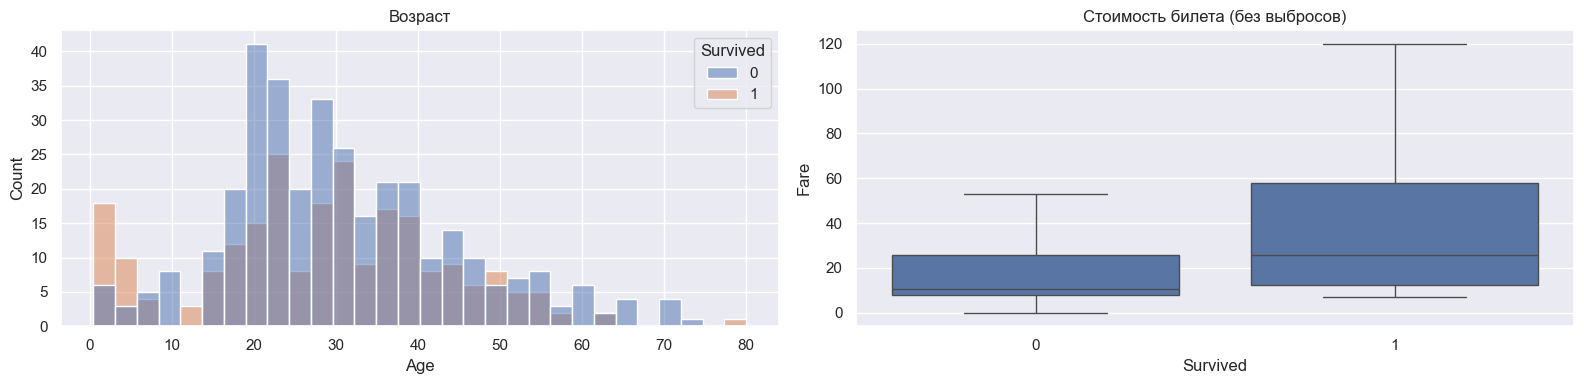

In [10]:
fig, axs = plt.subplots(figsize=(16, 4), ncols=2)
sns.histplot(data=train, x="Age", hue="Survived", bins=30, ax=axs[0])
axs[0].set_title("Возраст")
sns.boxplot(data=train, x="Survived", y="Fare", showfliers=False, color="C0", ax=axs[1])
axs[1].set_title("Стоимость билета (без выбросов)")
plt.tight_layout()

age_group = pd.cut(train["Age"], bins=[0, 12, 18, 30, 50, 80])
print(train.groupby(age_group)["Survived"].agg(["mean", "size"]).round(3))
print("\nВыживаемость при неизвестном возрасте: %.3f" % train.loc[train["Age"].isna(), "Survived"].mean())
print("\nFare по классам (медиана):")
print(train.groupby("Pclass")["Fare"].median())

Выводы:
- **Возраст**: дети до 12 лет выживали заметно чаще (60%), чем взрослые (30–44%). Это видно и на гистограмме — пик выживших в районе 0–5 лет. Для взрослых связь с возрастом слабая, так что зависимость нелинейная: важно, ребёнок пассажир или нет.
- **Пассажиры с неизвестным возрастом** выживали реже (29% против 38% в среднем): возраст чаще не записан у пассажиров третьего класса. Заполняю пропуски медианой, отдельный признак «возраст неизвестен» не добавляю — его связь с выживанием во многом объясняется классом.
- **Стоимость билета**: у выживших медианная цена выше примерно в 2.5 раза. Но `Fare` сильно связана с классом (медиана 58 в первом, 14.5 во втором и 8 в третьем) и во многом дублирует его. Ещё одна особенность: `Fare` — это цена **всего билета**, а по одному билету часто ехала целая группа, поэтому для попутчиков значение одинаковое и может быть завышенным. Распределение с очень длинным хвостом (максимум больше 500) — для SVM и KNN это важно учесть при масштабировании.

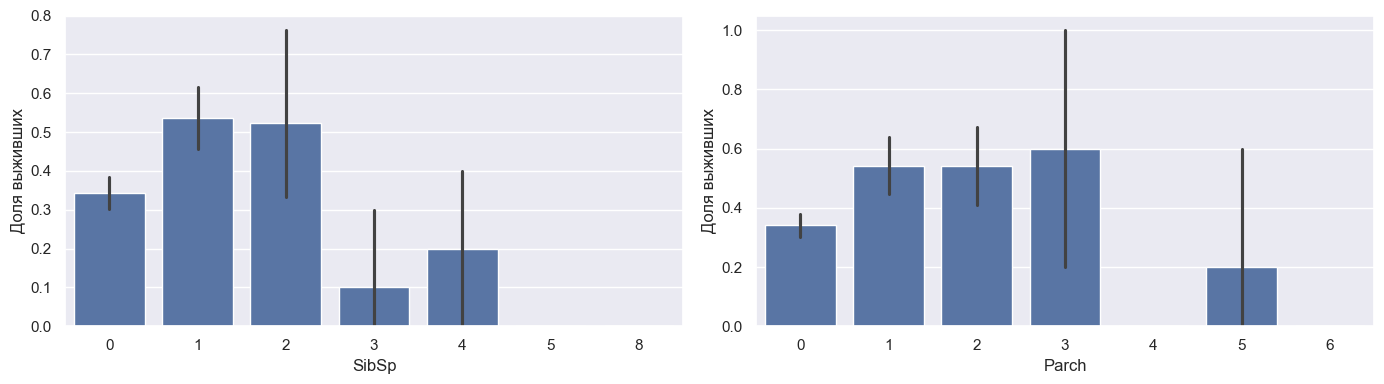

In [11]:
fig, axs = plt.subplots(figsize=(14, 4), ncols=2)
for i, feature in enumerate(["SibSp", "Parch"]):
    sns.barplot(data=train, x=feature, y="Survived", color="C0", ax=axs[i])
    axs[i].set_ylabel("Доля выживших")
plt.tight_layout()

Выводы: у пассажиров с 1–2 родственниками на борту выживаемость выше (~0.5), чем у тех, кто ехал один (~0.35), а у больших семей (3 и больше братьев/сестёр, 4 и больше родителей/детей) — очень низкая. Одиночки — это в основном мужчины третьего класса, а большие семьи — в основном семьи третьего класса, которым было сложнее всего добраться до шлюпок всем вместе. Зависимость нелинейная, но групп с большими семьями очень мало (несколько человек), поэтому выводы по ним ненадёжные. Признаки `SibSp` и `Parch` оставляю как есть.

Сам `Name` уникален и как признак бесполезен, но в нём есть обращение (Mr, Mrs, Miss, Master, ...), которое несёт информацию о поле, возрасте и семейном положении. Достану его в отдельный признак `Title`. Редкие обращения (Dr, Rev, Col, ...) объединю в группу `Rare`, а французские варианты приведу к английским (Mlle, Ms → Miss, Mme → Mrs).

Это построчное преобразование: оно ничего не «учит» по данным, поэтому его можно применить к train и test по отдельности, утечки нет.

In [12]:
def add_title(df):
    df = df.copy()
    title = df["Name"].str.extract(r",\s*([^\.]+)\.")[0]
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    df["Title"] = title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
    return df

X_train = add_title(X_train)
X_test = add_title(X_test)
train["Title"] = X_train["Title"]

print(train[["Name", "Title"]].head())
train.groupby("Title").agg(
    count=("Survived", "size"),
    survived=("Survived", "mean"),
    median_age=("Age", "median"),
).sort_values("count", ascending=False).round(3)

                                            Name Title
692                                 Lam, Mr. Ali    Mr
481             Frost, Mr. Anthony Wood "Archie"    Mr
527                           Farthing, Mr. John    Mr
855                   Aks, Mrs. Sam (Leah Rosen)   Mrs
801  Collyer, Mrs. Harvey (Charlotte Annie Tate)   Mrs


,count,survived,median_age
Title,,,
Mr,412,0.153,30.0
Miss,144,0.708,22.0
Mrs,107,0.785,35.0
Master,31,0.548,3.0
Rare,18,0.389,49.0


Выводы: обращение несёт сразу несколько вещей:
- `Mr` — взрослые мужчины, выжили только 15%;
- `Mrs` и `Miss` — замужние и незамужние женщины, выжили 79% и 71%;
- `Master` — так обращались к мальчикам (медианный возраст 3 года), и они выживали в 3.5 раза чаще, чем взрослые мужчины (55%). Пол у них мужской, поэтому один признак `Sex` этого не видит, а `Title` различает мальчиков и взрослых мужчин даже тогда, когда возраст неизвестен;
- `Rare` — военные, врачи, священники, знать (медианный возраст 49).

Т.е. `Title` — это в основном комбинация пола и возраста, и он частично дублирует `Sex`. Пассажира он не идентифицирует (всего 5 групп), так что это нормальный признак.

Отдельно посмотрю на `Cabin`: у 77% пассажиров каюта неизвестна, но, может быть, сам факт, что она известна, что-то значит.

In [13]:
train["HasCabin"] = train["Cabin"].notna().astype(int)

print("Доля пассажиров с известной каютой по классам:")
print(train.groupby("Pclass")["HasCabin"].mean().round(3))
print("\nДоля выживших в зависимости от того, известна ли каюта:")
print(train.pivot_table(index="Pclass", columns="HasCabin", values="Survived", aggfunc=["mean", "size"]).round(3))

Доля пассажиров с известной каютой по классам:
Pclass
1    0.795
2    0.100
3    0.023
Name: HasCabin, dtype: float64

Доля выживших в зависимости от того, известна ли каюта:
           mean        size     
HasCabin      0      1    0    1
Pclass                          
1         0.457  0.699   35  136
2         0.407  0.800  135   15
3         0.236  0.556  382    9


Выводы: каюта известна почти только у первого класса (80%), во втором и третьем — у единиц. Но даже **внутри одного класса** пассажиры с известной каютой выживали намного чаще: в первом классе 70% против 46%, во втором 80% против 41%.

Это подозрительно. Номера кают в этих данных во многом восстанавливали уже после катастрофы, в том числе по рассказам выживших, поэтому каюта чаще известна именно у тех, кто выжил. Получается, что признак «каюта известна» может нести информацию, которая появилась **из-за** исхода, т.е. это утечка целевой переменной. Поэтому ни `Cabin`, ни производные от неё признаки я не использую. В части 15 отдельно проверю, что было бы, если бы этот признак добавили.

### Что я беру из анализа данных в моделирование
1. Классы несбалансированы (62% / 38%) — основная метрика F1, а не Accuracy; разбиение стратифицированное.
2. Главные признаки — пол, класс, возраст (дети), стоимость билета; между полом и классом есть сильное взаимодействие.
3. Из `Name` достаю признак `Title`: он различает мальчиков и взрослых мужчин. Нужен ли он на самом деле, проверю по кросс-валидации в части 12.
4. Не использую признаки-идентификаторы `PassengerId`, `Name`, `Ticket` и подозрительную `Cabin`.
5. Пропуски: `Age` — медиана, `Embarked` — самый частый порт. Все параметры заполнения считаются только по train.
6. В итоге в модель идут: числовые `Age`, `Fare`, `SibSp`, `Parch` и категориальные `Pclass`, `Sex`, `Embarked`, `Title`.

# Часть 4. Подготовка признаков

Подготовку собираю в `ColumnTransformer`:
- **числовые** (`Age`, `Fare`, `SibSp`, `Parch`) — пропуски заполняю медианой (`SimpleImputer(strategy="median")`): медиана устойчива к выбросам, а у `Fare` они большие;
- **категориальные** (`Pclass`, `Sex`, `Embarked`, `Title`) — пропуски заполняю самым частым значением, затем `OneHotEncoder`. One-hot нужен, потому что модели работают только с числами, а просто пронумеровать категории (S = 0, C = 1, Q = 2) было бы неправильно: появился бы несуществующий порядок. `Pclass` тоже кодирую one-hot: его связь с выживанием не обязана быть «линейной по номеру класса». `handle_unknown="ignore"` нужен на случай, если в тесте встретится категория, которой не было в train.

Препроцессор делаю в двух вариантах — без масштабирования для деревьев и со `StandardScaler` для SVM и KNN. Препроцессор всегда стоит внутри `Pipeline` вместе с моделью, поэтому медианы, самые частые значения и параметры масштабирования считаются только по обучающей части (а при кросс-валидации — только по обучающим фолдам). Колонки, которых нет в списках (`PassengerId`, `Name`, `Ticket`, `Cabin`), `ColumnTransformer` просто отбрасывает.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric = ["Age", "Fare", "SibSp", "Parch"]
categorical = ["Pclass", "Sex", "Embarked", "Title"]

def make_preprocess(scale, cat_features=categorical):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), numeric),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_features)
    ])

prep = make_preprocess(scale=False)
prep_scaled = make_preprocess(scale=True)

X_ready = prep.fit_transform(X_train)
print(X_train[numeric + categorical].shape, "->", X_ready.shape)
print(list(prep.get_feature_names_out()))

(712, 8) -> (712, 17)
['num__Age', 'num__Fare', 'num__SibSp', 'num__Parch', 'cat__Pclass_1', 'cat__Pclass_2', 'cat__Pclass_3', 'cat__Sex_female', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S', 'cat__Title_Master', 'cat__Title_Miss', 'cat__Title_Mr', 'cat__Title_Mrs', 'cat__Title_Rare']


In [15]:
pd.DataFrame(prep_scaled.fit_transform(X_train), columns=prep_scaled.get_feature_names_out()).describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
num__Age,0.000,1.001,-2.238,3.875
num__Fare,-0.000,1.001,-0.663,10.005
num__SibSp,-0.000,1.001,-0.465,7.082
num__Parch,-0.000,1.001,-0.466,6.698
cat__Pclass_1,0.240,0.427,0.000,1.000
cat__Pclass_2,0.211,0.408,0.000,1.000
cat__Pclass_3,0.549,0.498,0.000,1.000
cat__Sex_female,0.355,0.479,0.000,1.000
cat__Sex_male,0.645,0.479,0.000,1.000
cat__Embarked_C,0.195,0.397,0.000,1.000


**Для каких алгоритмов важно масштабирование.**
- **Деревья (Decision Tree, Random Forest, Gradient Boosting) — не нужно.** Разбиение — это порог вида «признак < t», и при монотонном преобразовании признака меняется только значение порога, а не само разбиение. Деревья сравнивают значения одного признака между собой и никогда не складывают разные признаки.
- **SVM и KNN — нужно обязательно.** Оба метода работают с расстояниями (KNN) или скалярными произведениями (SVM с RBF-ядром — тоже через расстояния) между объектами в пространстве признаков. Без масштабирования `Fare` (от 0 до 512) по вкладу в расстояние полностью задавит `Age` (0–80) и тем более one-hot признаки (0 или 1): разница в 20 фунтов в цене билета для модели будет «в 20 раз важнее», чем разница полов. После `StandardScaler` числовые признаки имеют среднее 0 и std 1 (таблица выше), а one-hot признаки и так от 0 до 1, т.е. все признаки в сопоставимом масштабе. Ниже, в частях 10 и 11, я проверяю это на практике.

Признак `Title` добавляю во все модели. Действительно ли он нужен, проверю по кросс-валидации в части 12: для каждой модели повторю тот же случайный поиск гиперпараметров, но без `Title`, и сравню лучший CV F1.

# Часть 5. Метрики

Положительный класс — «выжил» (1). Через элементы confusion matrix:
- **TP** — выжил, и модель сказала «выжил»; **TN** — погиб, и модель сказала «погиб»;
- **FP (False Positive)** — пассажир **погиб**, а модель сказала «выжил»;
- **FN (False Negative)** — пассажир **выжил**, а модель сказала «погиб».

Метрики:
- **Accuracy** $= \frac{TP + TN}{TP + TN + FP + FN}$ — доля всех правильных ответов. Удобна, но обманчива при дисбалансе: константа «погиб» даёт 0.62.
- **Precision** $= \frac{TP}{TP + FP}$ — из тех, кого модель назвала выжившими, сколько действительно выжили. Падает из-за FP.
- **Recall** $= \frac{TP}{TP + FN}$ — из всех реально выживших сколько модель нашла. Падает из-за FN.
- **F1** $= \frac{2 \cdot Precision \cdot Recall}{Precision + Recall}$ — гармоническое среднее Precision и Recall. Оно высокое, только если обе метрики высокие: модель, которая всем говорит «выжил», получит Recall = 1, но низкий Precision и средний F1, а модель, которая всем говорит «погиб», получит F1 = 0.
- **ROC-AUC** считаю для справки: она показывает, насколько хорошо модель ранжирует пассажиров по «шансу выжить», независимо от порога 0.5.

**Чем различаются FP и FN в этой задаче.** FP — модель «спасла» того, кто на самом деле погиб, FN — «похоронила» того, кто выжил. Если представить, что модель используется, например, чтобы понять, кого искать среди выживших, то FN хуже: мы перестанем искать живого человека. Если же нужно оценить, сколько людей спаслось, FP завышают эту оценку. В лабораторной обе ошибки одинаково важны, поэтому и выбрана F1, которая учитывает и Precision (FP), и Recall (FN).

Для удобства заведу функцию, которая считает все метрики на тесте и складывает их в общую таблицу (туда же записываю CV F1 на train), и функцию для отрисовки confusion matrix.

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

results = {}
predictions = {}

def evaluate(name, model, cv_f1=np.nan):
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, scores),
        "CV F1": cv_f1,
    }
    predictions[name] = y_pred
    print("%s: Accuracy = %.4f, Precision = %.4f, Recall = %.4f, F1 = %.4f, ROC-AUC = %.4f" % (
        name, results[name]["Accuracy"], results[name]["Precision"], results[name]["Recall"], results[name]["F1"], results[name]["ROC-AUC"]))

def show_confusion(name):
    cm = confusion_matrix(y_test, predictions[name])
    ConfusionMatrixDisplay(cm, display_labels=["погиб (0)", "выжил (1)"]).plot(cmap="Blues", colorbar=False)
    plt.title(name)
    plt.grid(False)
    tn, fp, fn, tp = cm.ravel()
    print("TN = %d, FP = %d, FN = %d, TP = %d" % (tn, fp, fn, tp))

**Схема валидации.** Все решения (признаки, гиперпараметры, выбор лучшей модели) принимаю по стратифицированной кросс-валидации на train: 5 фолдов с перемешиванием и фиксированным `random_state`, один и тот же объект `cv` для всех моделей, чтобы они сравнивались на одинаковых разбиениях. Стратификация нужна, чтобы в каждом фолде доля выживших была такой же, как во всём train.

Гиперпараметры всех моделей подбираю случайным поиском (`RandomizedSearchCV`) по F1. Чтобы не повторять один и тот же код пять раз, заведу функцию: она собирает `Pipeline` из препроцессора и модели и запускает поиск. Тест используется только для финальной оценки.

In [17]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_score, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def run_search(model, params, scale, cat_features=categorical, n_iter=30, verbose=True):
    searcher = RandomizedSearchCV(
        Pipeline([("prep", make_preprocess(scale, cat_features)), ("model", model)]),
        params,
        n_iter=n_iter,
        scoring="f1",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    searcher.fit(X_train, y_train)
    if verbose:
        print("Best params:", searcher.best_params_)
        print("Best CV F1 = %.4f" % searcher.best_score_)
    return searcher

# Часть 6. Baseline

`DummyClassifier(strategy="most_frequent")` всегда предсказывает самый частый класс в train, т.е. «погиб».

Baseline: Accuracy = 0.6145, Precision = 0.0000, Recall = 0.0000, F1 = 0.0000, ROC-AUC = 0.5000
TN = 110, FP = 0, FN = 69, TP = 0


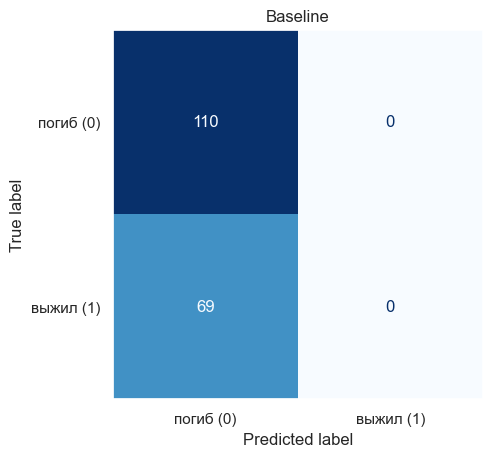

In [18]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent")
cv_scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1")
baseline.fit(X_train, y_train)

evaluate("Baseline", baseline, np.mean(cv_scores))
show_confusion("Baseline")

Вывод: baseline получает Accuracy 0.615 — больше половины ответов правильные, — но при этом не находит ни одного выжившего: Precision, Recall и F1 равны нулю, а все 69 выживших в тесте — это FN. ROC-AUC = 0.5, как у случайного угадывания. Это наглядно показывает, почему Accuracy здесь не подходит как основная метрика: любая модель должна заметно превзойти 0.615 по Accuracy, а главное — получить F1 > 0.70.

# Часть 7. Decision Tree

Решающее дерево задаёт последовательность вопросов вида «признак < порог?» и в каждом листе выдаёт самый частый класс. Разбиение в каждом узле выбирается так, чтобы дочерние узлы были как можно «чище» (по критерию Gini или энтропии). Дерево без ограничений может разбивать данные, пока в каждом листе не останется один класс, т.е. просто запомнить train.

Сначала посмотрю на дерево без ограничений, потом — как качество зависит от глубины, и потом подберу гиперпараметры случайным поиском.

In [19]:
from sklearn.tree import DecisionTreeClassifier

full_tree = Pipeline([
    ("prep", make_preprocess(scale=False)),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
])

cv_res = cross_validate(full_tree, X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
print("Дерево без ограничений: Train F1 = %.4f, CV F1 = %.4f" % (cv_res["train_score"].mean(), cv_res["test_score"].mean()))

full_tree.fit(X_train, y_train)
print("Глубина = %d, листьев = %d" % (full_tree.named_steps["model"].get_depth(), full_tree.named_steps["model"].get_n_leaves()))

Дерево без ограничений: Train F1 = 0.9786, CV F1 = 0.6992
Глубина = 18, листьев = 153


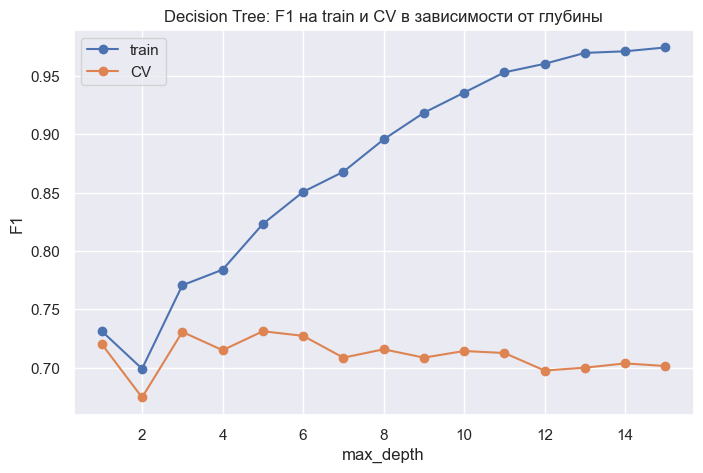

In [20]:
depths = range(1, 16)
train_scores, cv_scores = [], []
for depth in depths:
    tree = Pipeline([
        ("prep", make_preprocess(scale=False)),
        ("model", DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE))
    ])
    res = cross_validate(tree, X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
    train_scores.append(res["train_score"].mean())
    cv_scores.append(res["test_score"].mean())

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, "o-", label="train")
plt.plot(depths, cv_scores, "o-", label="CV")
plt.xlabel("max_depth")
plt.ylabel("F1")
plt.title("Decision Tree: F1 на train и CV в зависимости от глубины")
plt.legend()

Вывод: дерево без ограничений выросло до глубины 18 и 153 листьев: на train F1 = 0.98, а на кросс-валидации всего 0.70. Это классическое переобучение — дерево запомнило обучающих пассажиров вместе с шумом.

На графике хорошо видно, как это происходит: с ростом глубины F1 на train растёт почти до 1, а на CV лучшие значения (~0.73) получаются при глубине 3–6, после чего качество падает. Разрыв между кривыми — это и есть переобучение. Значит, сложность дерева нужно ограничивать: глубиной, минимальным числом объектов в листе и т.д.

In [21]:
from scipy.stats import randint, uniform, loguniform

tree_params = {
    "model__max_depth": randint(2, 12),
    "model__min_samples_leaf": randint(1, 30),
    "model__min_samples_split": randint(2, 30),
    "model__criterion": ["gini", "entropy"],
    "model__class_weight": [None, "balanced"],
}

tree_searcher = run_search(DecisionTreeClassifier(random_state=RANDOM_STATE), tree_params, scale=False, n_iter=50)

Best params: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 8, 'model__min_samples_leaf': 2, 'model__min_samples_split': 4}
Best CV F1 = 0.7612


Train: F1 = 0.8663, Accuracy = 0.8947
Decision Tree: Accuracy = 0.7877, Precision = 0.7123, Recall = 0.7536, F1 = 0.7324, ROC-AUC = 0.8205
TN = 89, FP = 21, FN = 17, TP = 52


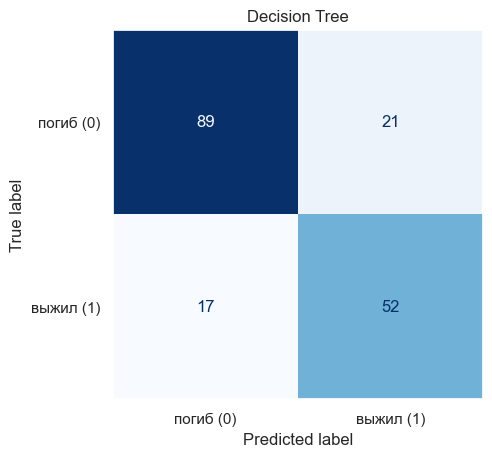

In [22]:
tree_model = tree_searcher.best_estimator_

print("Train: F1 = %.4f, Accuracy = %.4f" % (f1_score(y_train, tree_model.predict(X_train)), accuracy_score(y_train, tree_model.predict(X_train))))
evaluate("Decision Tree", tree_model, tree_searcher.best_score_)
show_confusion("Decision Tree")

Вывод:
- Лучшая комбинация: `max_depth=8`, `min_samples_leaf=2`, `min_samples_split=4`, `criterion="entropy"` и `class_weight="balanced"`. Последнее значит, что ошибки на редком классе «выжил» штрафуются сильнее, и дерево чаще предсказывает «выжил»: Recall вырос (0.754), а Precision ниже (0.712). Это видно и в confusion matrix: FP (21) больше, чем FN (17) — у других моделей обычно наоборот.
- CV F1 = 0.761, на тесте F1 = 0.732, Accuracy = 0.788. Порог 0.70 пройден.
- **Есть признаки переобучения**: на train F1 = 0.87 и Accuracy = 0.89, на тесте F1 = 0.73 и Accuracy = 0.79. Разрыв ~0.13 по F1 заметный, хотя гораздо меньше, чем у дерева без ограничений (0.98 против 0.70). Одно дерево — неустойчивая модель с большим разбросом: даже ограниченное, оно подстраивается под конкретную выборку. Это как раз то, что исправляют ансамбли.

На рисунке ниже верхние уровни подобранного дерева (из-за `class_weight="balanced"` доли классов в узлах взвешенные, поэтому в корне 0.5 / 0.5). Первый вопрос — «это взрослый мужчина (`Title_Mr`)?». Для не-мужчин дальше спрашивается класс (третий или нет), для мужчин — цена билета и возраст. Это полностью совпадает с выводами EDA: сначала пол/возраст, потом класс.

Text(0.5, 1.0, 'Верхние уровни подобранного дерева')

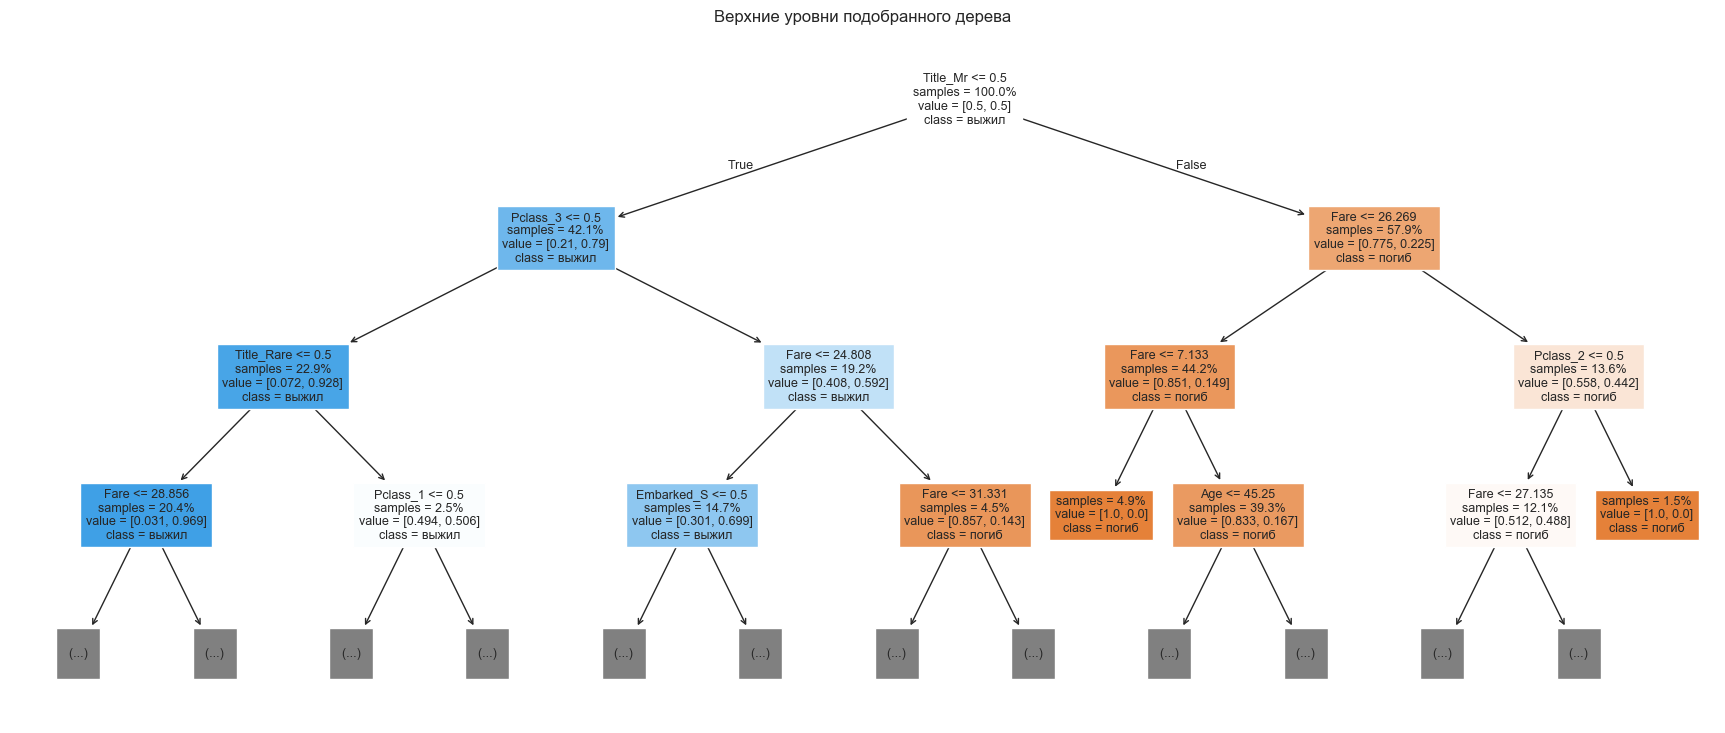

In [23]:
from sklearn.tree import plot_tree

def feature_names(model):
    return [name.split("__")[1] for name in model.named_steps["prep"].get_feature_names_out()]

plt.figure(figsize=(22, 9))
plot_tree(tree_model.named_steps["model"], feature_names=feature_names(tree_model), class_names=["погиб", "выжил"],
          max_depth=3, filled=True, fontsize=9, impurity=False, proportion=True)
plt.title("Верхние уровни подобранного дерева")

Title_Mr        0.370
Fare            0.260
Age             0.144
Pclass_3        0.089
Title_Rare      0.045
Title_Miss      0.021
Pclass_2        0.019
Embarked_S      0.019
Pclass_1        0.017
Parch           0.011
Title_Mrs       0.004
Sex_female      0.002
SibSp           0.000
Sex_male        0.000
Title_Master    0.000
Embarked_C      0.000
Embarked_Q      0.000
dtype: float64

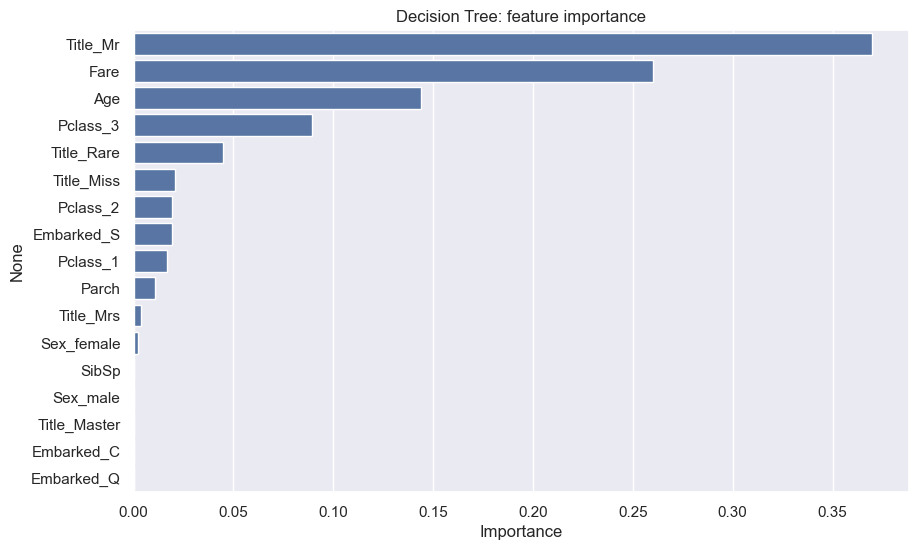

In [24]:
def get_importances(model):
    return pd.Series(model.named_steps["model"].feature_importances_, index=feature_names(model)).sort_values(ascending=False)

tree_importances = get_importances(tree_model)

plot = sns.barplot(y=tree_importances.index, x=tree_importances, color="C0")
plot.figure.set_size_inches(10, 6)
plt.title("Decision Tree: feature importance")
plt.xlabel("Importance")

tree_importances.round(3)

`feature_importances_` дерева (MDI) показывает, насколько суммарно уменьшилась неоднородность (impurity) в узлах за счёт разбиений по признаку (нормировано на 1).

Выводы:
- Самый важный признак — `Title_Mr` (0.37), т.е. «взрослый мужчина или нет». Дальше `Fare` (0.26), `Age` (0.14) и `Pclass_3` (0.09).
- `Sex` у дерева почти нулевой. Это не значит, что пол не важен: `Title_Mr` уже содержит информацию о поле (и возрасте), и дерево выбрало его в корне вместо `Sex`. Когда два признака дублируют друг друга, дерево берёт один и «отдаёт» ему всю важность.
- `Fare` важнее, чем `Pclass`, хотя в EDA класс выглядел не слабее. Цена билета — непрерывный признак с сотнями значений, по нему можно сделать много разных порогов, и MDI такие признаки систематически завышает. Кроме того, `Fare` частично заменяет класс.

# Часть 8. Random Forest

Случайный лес обучает много глубоких деревьев, каждое — на своей бутстрап-выборке объектов и с выбором из случайного подмножества признаков в каждом узле, а затем усредняет их ответы (голосование). Отдельные деревья переобучаются по-разному, и при усреднении их ошибки частично компенсируются — разброс (variance) уменьшается, а смещение остаётся как у глубокого дерева.

Подбираю через `RandomizedSearchCV` на тех же 5 фолдах: число деревьев, глубину, минимальный размер листа, `max_features` и `class_weight`. Масштабирование не нужно.

In [25]:
from sklearn.ensemble import RandomForestClassifier

rf_params = {
    "model__n_estimators": randint(100, 600),
    "model__max_depth": [None, 4, 6, 8, 10, 15],
    "model__min_samples_leaf": randint(1, 10),
    "model__max_features": ["sqrt", 0.3, 0.5, 0.7, 1.0],
    "model__class_weight": [None, "balanced"],
}

rf_searcher = run_search(RandomForestClassifier(random_state=RANDOM_STATE), rf_params, scale=False, n_iter=30)

Best params: {'model__class_weight': 'balanced', 'model__max_depth': 15, 'model__max_features': 0.5, 'model__min_samples_leaf': 3, 'model__n_estimators': 548}
Best CV F1 = 0.7686


Train: F1 = 0.8780, Accuracy = 0.9087
Random Forest: Accuracy = 0.8101, Precision = 0.7612, Recall = 0.7391, F1 = 0.7500, ROC-AUC = 0.8436
TN = 94, FP = 16, FN = 18, TP = 51


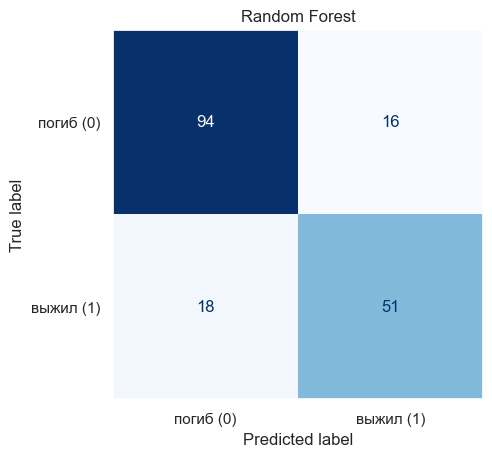

In [26]:
rf_model = rf_searcher.best_estimator_

print("Train: F1 = %.4f, Accuracy = %.4f" % (f1_score(y_train, rf_model.predict(X_train)), accuracy_score(y_train, rf_model.predict(X_train))))
evaluate("Random Forest", rf_model, rf_searcher.best_score_)
show_confusion("Random Forest")

Вывод:
- Лучшая комбинация: 548 деревьев, `max_depth=15`, `min_samples_leaf=3`, `max_features=0.5`, `class_weight="balanced"`. CV F1 = 0.769, на тесте F1 = 0.750, Accuracy = 0.810. Порог пройден.
- По сравнению с деревом лес лучше на CV (0.769 против 0.761) и на тесте (0.750 против 0.732), и ошибки у него более сбалансированы: FP 16 и FN 18 (у дерева 21 и 17).
- Разрыв между train (F1 = 0.88) и тестом (0.75) у леса тоже есть. Для леса это нормально: он состоит из глубоких деревьев и хорошо подстраивается под train, а важна оценка на новых данных, и по CV и тесту лес стабильнее одного дерева.

,Decision Tree,Random Forest
Fare,0.260,0.202
Title_Mr,0.370,0.200
Age,0.144,0.151
Sex_female,0.002,0.131
Sex_male,0.000,0.087
Pclass_3,0.089,0.052
SibSp,0.000,0.048
Pclass_1,0.017,0.028
Parch,0.011,0.018
Embarked_S,0.019,0.016


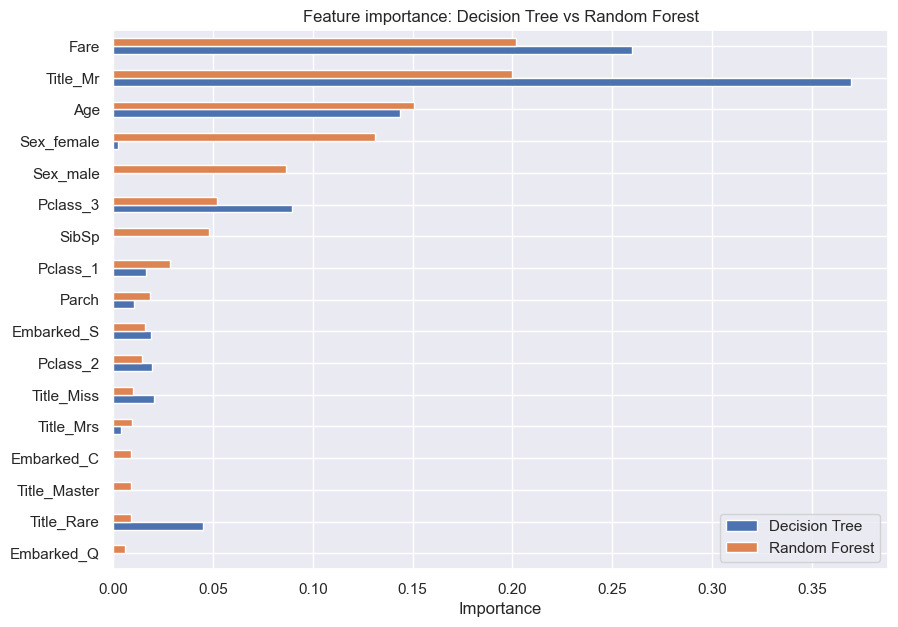

In [27]:
rf_importances = get_importances(rf_model)

importances = pd.DataFrame({"Decision Tree": tree_importances, "Random Forest": rf_importances}).sort_values("Random Forest")
importances.plot(kind="barh", figsize=(10, 7))
plt.title("Feature importance: Decision Tree vs Random Forest")
plt.xlabel("Importance")

importances.sort_values("Random Forest", ascending=False).round(3)

Выводы (сравнение с Decision Tree):
- У леса важность распределена гораздо равномернее: `Fare` (0.20), `Title_Mr` (0.20), `Age` (0.15), `Sex_female` (0.13), `Sex_male` (0.09). У дерева почти всё забрали `Title_Mr` и `Fare`.
- Главное отличие — **пол**: у дерева `Sex` почти не используется, а у леса пол на 4–5 местах. В лесу при каждом разбиении доступна только половина признаков (`max_features=0.5`), и когда `Title_Mr` не попал в подмножество, дерево берёт его «заместителя» — `Sex`. Поэтому у леса важность делится между двумя дублирующими признаками.
- Общий набор главных признаков совпадает: пол/обращение, цена билета, возраст и третий класс.

# Часть 9. Gradient Boosting

Градиентный бустинг строит деревья последовательно: каждое следующее неглубокое дерево обучается исправлять ошибки уже построенного ансамбля (приближает антиградиент функции потерь — для классификации это log-loss), и его вклад умножается на `learning_rate`. В отличие от леса, где деревья независимые и глубокие, бустинг в основном уменьшает смещение.

Подбираю через `RandomizedSearchCV`: число деревьев и `learning_rate` (они связаны: чем меньше шаг, тем больше нужно деревьев), глубину деревьев, минимальный размер листа и `subsample` (доля объектов для каждого дерева).

In [28]:
from sklearn.ensemble import GradientBoostingClassifier

gb_params = {
    "model__n_estimators": randint(50, 500),
    "model__learning_rate": loguniform(0.01, 0.3),
    "model__max_depth": randint(1, 6),
    "model__min_samples_leaf": randint(1, 20),
    "model__subsample": uniform(0.6, 0.4),
}

gb_searcher = run_search(GradientBoostingClassifier(random_state=RANDOM_STATE), gb_params, scale=False, n_iter=30)

Best params: {'model__learning_rate': np.float64(0.14447746112718687), 'model__max_depth': 3, 'model__min_samples_leaf': 12, 'model__n_estimators': 104, 'model__subsample': np.float64(0.9932923543227152)}
Best CV F1 = 0.7731


Train: F1 = 0.8821, Accuracy = 0.9129
Gradient Boosting: Accuracy = 0.8380, Precision = 0.8333, Recall = 0.7246, F1 = 0.7752, ROC-AUC = 0.8351
TN = 100, FP = 10, FN = 19, TP = 50


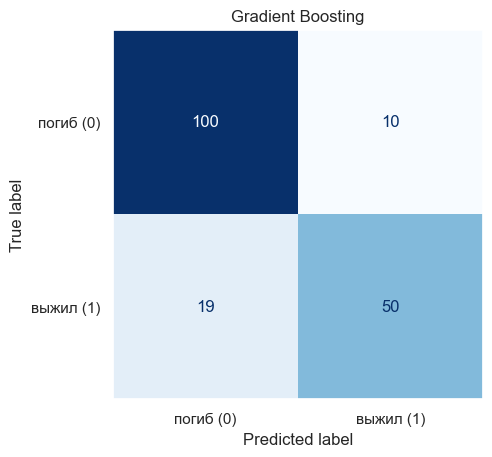

In [29]:
gb_model = gb_searcher.best_estimator_

print("Train: F1 = %.4f, Accuracy = %.4f" % (f1_score(y_train, gb_model.predict(X_train)), accuracy_score(y_train, gb_model.predict(X_train))))
evaluate("Gradient Boosting", gb_model, gb_searcher.best_score_)
show_confusion("Gradient Boosting")

Вывод:
- Лучшая комбинация: 104 дерева глубины 3, `learning_rate` ≈ 0.14, `min_samples_leaf=12`, `subsample` ≈ 0.99. Неглубокие деревья и довольно большие листья — бустинг здесь сильно регуляризован, что логично для маленького датасета.
- CV F1 = 0.773 — лучший результат на кросс-валидации среди всех моделей. На тесте F1 = 0.775, Accuracy = 0.838, Precision = 0.833 — самая высокая точность среди деревьев.
- Ошибки: FP всего 10, зато FN 19. Т.е. бустинг осторожнее называет пассажира выжившим: если уж сказал «выжил», то почти наверняка прав, но часть выживших пропускает.
- Разрыв train (0.88) и тест (0.78) меньше, чем у дерева и леса: бустинг с неглубокими деревьями и большими листьями переобучается меньше.
- По сравнению с лесом бустинг немного лучше и на CV (0.773 против 0.769), и на тесте (0.775 против 0.750), но разница на CV очень маленькая.

,Random Forest,Gradient Boosting
Title_Mr,0.200,0.445
Fare,0.202,0.228
Pclass_3,0.052,0.113
Age,0.151,0.092
Title_Rare,0.009,0.038
Embarked_S,0.016,0.018
Sex_female,0.131,0.015
Pclass_1,0.028,0.013
SibSp,0.048,0.013
Sex_male,0.087,0.009


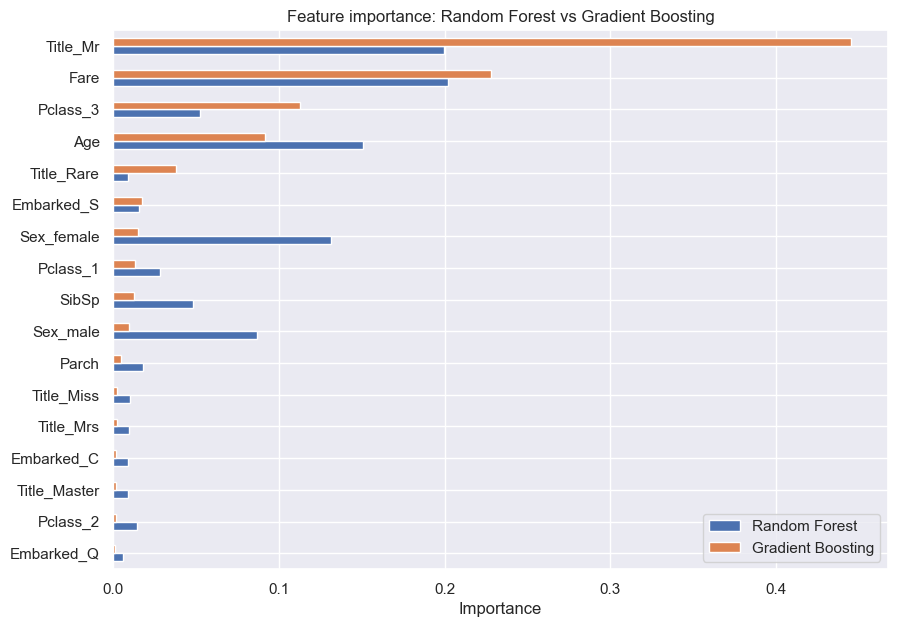

In [30]:
gb_importances = get_importances(gb_model)

importances = pd.DataFrame({"Random Forest": rf_importances, "Gradient Boosting": gb_importances}).sort_values("Gradient Boosting")
importances.plot(kind="barh", figsize=(10, 7))
plt.title("Feature importance: Random Forest vs Gradient Boosting")
plt.xlabel("Importance")

importances.sort_values("Gradient Boosting", ascending=False).round(3)

Выводы (сравнение с Random Forest):
- У бустинга, как и у одиночного дерева, важность сосредоточена в нескольких признаках: `Title_Mr` (0.45), `Fare` (0.23), `Pclass_3` (0.11), `Age` (0.09). У леса она размазана по большему числу признаков.
- Снова видна история с полом: бустинг почти не использует `Sex` (0.015 + 0.009), потому что первое же дерево берёт `Title_Mr`, а дальше пол уже ничего нового не добавляет. Лес же из-за случайного выбора признаков часто использует `Sex` вместо `Title_Mr`.
- `Pclass_3` у бустинга в 2 раза важнее, чем у леса: бустинг последовательно исправляет ошибки, и после «пола» главная оставшаяся ошибка — это как раз женщины третьего класса, которые выживали гораздо реже остальных женщин.
- Набор главных признаков у обеих моделей одинаковый: обращение/пол, цена билета, класс и возраст.

# Часть 10. Support Vector Machine

SVM ищет разделяющую поверхность с максимальным зазором (margin) между классами. Параметр `C` задаёт компромисс между шириной зазора и ошибками на train (большой `C` — меньше регуляризации, граница сильнее подстраивается под train). С ядром RBF граница может быть нелинейной, а `gamma` задаёт, насколько «локальным» будет влияние каждого объекта.

**Нужно ли масштабирование?** Да, обязательно. И зазор, и RBF-ядро $K(x, x') = \exp(-\gamma \|x - x'\|^2)$ считаются через расстояния между объектами. Если признаки в разных масштабах, расстояние почти полностью определяется признаком с самым большим разбросом — здесь это `Fare`. Проверю это сравнением на кросс-валидации.

In [31]:
from sklearn.svm import SVC

for prep_name, scale in [("без масштабирования", False), ("со StandardScaler", True)]:
    svm = Pipeline([("prep", make_preprocess(scale)), ("model", SVC())])
    print("SVC %s: CV F1 = %.4f" % (prep_name, cross_val_score(svm, X_train, y_train, cv=cv, scoring="f1").mean()))

SVC без масштабирования: CV F1 = 0.4493
SVC со StandardScaler: CV F1 = 0.7535


Вывод: разница огромная — SVC с параметрами по умолчанию без масштабирования получает CV F1 = 0.45, а со `StandardScaler` — 0.75. Без масштабирования модель фактически смотрит только на цену билета, а пол и класс (0/1) для неё почти не отличаются по сравнению с разницей в десятки фунтов.

In [32]:
svm_params = {
    "model__C": loguniform(0.01, 100),
    "model__gamma": loguniform(1e-3, 1),
    "model__kernel": ["rbf", "linear"],
    "model__class_weight": [None, "balanced"],
}

# с линейным ядром и большим C libsvm на некоторых фолдах сходится очень долго, поэтому ограничиваю число итераций
svm_searcher = run_search(SVC(max_iter=100_000), svm_params, scale=True, n_iter=40)

Best params: {'model__C': np.float64(3.550012525851161), 'model__class_weight': None, 'model__gamma': np.float64(0.04827588872094673), 'model__kernel': 'rbf'}
Best CV F1 = 0.7722


Train: F1 = 0.7799, Accuracy = 0.8399
SVM: Accuracy = 0.8436, Precision = 0.8254, Recall = 0.7536, F1 = 0.7879, ROC-AUC = 0.8586
TN = 99, FP = 11, FN = 17, TP = 52


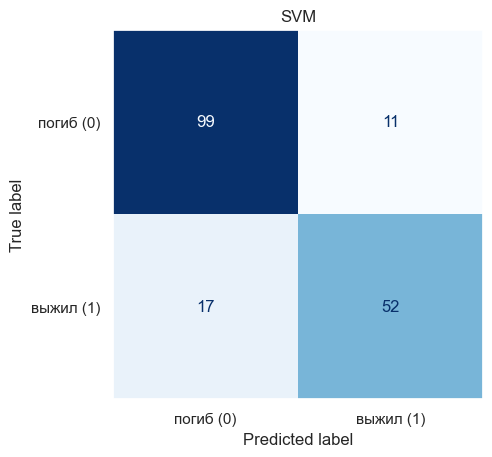

In [33]:
svm_model = svm_searcher.best_estimator_

print("Train: F1 = %.4f, Accuracy = %.4f" % (f1_score(y_train, svm_model.predict(X_train)), accuracy_score(y_train, svm_model.predict(X_train))))
evaluate("SVM", svm_model, svm_searcher.best_score_)
show_confusion("SVM")

Вывод:
- Лучшая комбинация: ядро RBF, `C` ≈ 3.6, `gamma` ≈ 0.048 (довольно гладкая граница), без `class_weight`. CV F1 = 0.772 — практически как у бустинга (0.773).
- На тесте у SVM лучший результат среди всех моделей: F1 = 0.788, Accuracy = 0.844, Precision = 0.825, Recall = 0.754, ROC-AUC = 0.859. Ошибки: FP 11, FN 17.
- Переобучения нет: на train F1 = 0.78, т.е. даже чуть ниже, чем на тесте. Гладкая граница с умеренным `C` хорошо обобщает, и тест, видимо, оказался для SVM немного «удачным» — на CV SVM и бустинг равны.

# Часть 11. K-Nearest Neighbors

KNN не строит модель как таковую: чтобы классифицировать нового пассажира, он находит `k` самых похожих пассажиров из train (ближайших по расстоянию в пространстве признаков) и голосует по их классам. Главный гиперпараметр — `k`: маленькое `k` — очень локальное решение и большой разброс, большое — гладкая граница и большее смещение. Ещё можно подбирать веса соседей (`weights="distance"` — ближние весят больше) и метрику расстояния (`p=1` — манхэттенская, `p=2` — евклидова).

**Почему масштаб особенно важен для KNN.** Весь алгоритм — это расстояние $\sqrt{\sum_j (x_j - x'_j)^2}$, и в нём все признаки складываются с одинаковым весом. Если один признак измеряется в сотнях (`Fare`), а другие — в единицах или 0/1 (пол, класс), то «ближайшие соседи» будут просто пассажирами с похожей ценой билета, независимо от пола и класса. Т.е. масштаб признака напрямую определяет его важность, и без масштабирования выбор соседей становится бессмысленным.

In [34]:
from sklearn.neighbors import KNeighborsClassifier

for prep_name, scale in [("без масштабирования", False), ("со StandardScaler", True)]:
    knn = Pipeline([("prep", make_preprocess(scale)), ("model", KNeighborsClassifier())])
    print("KNN %s: CV F1 = %.4f" % (prep_name, cross_val_score(knn, X_train, y_train, cv=cv, scoring="f1").mean()))

KNN без масштабирования: CV F1 = 0.6259
KNN со StandardScaler: CV F1 = 0.7325


Вывод: без масштабирования CV F1 = 0.63, со `StandardScaler` — 0.73. Масштабирование даёт +0.1 к F1, т.е. без него KNN заметно хуже. Для SVM эффект был ещё сильнее (0.45 → 0.75).

Best params: {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'uniform'}
Best CV F1 = 0.7469


Text(0.5, 1.0, 'KNN: подбор числа соседей')

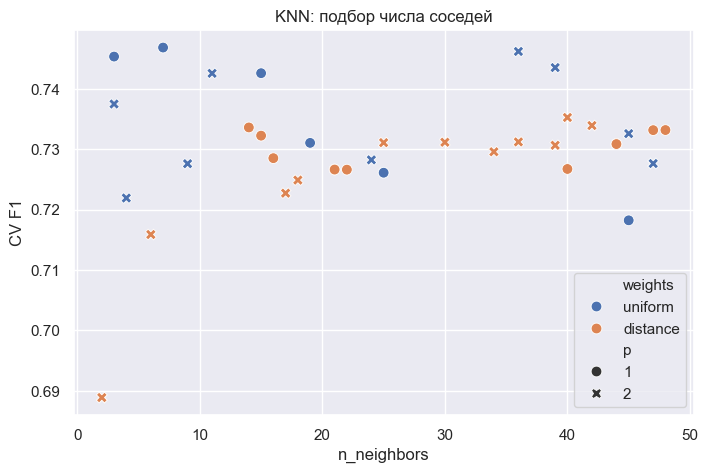

In [35]:
knn_params = {
    "model__n_neighbors": randint(1, 50),
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2],
}

knn_searcher = run_search(KNeighborsClassifier(), knn_params, scale=True, n_iter=40)

knn_cv_results = pd.DataFrame(knn_searcher.cv_results_).rename(columns={
    "param_model__n_neighbors": "n_neighbors",
    "param_model__weights": "weights",
    "param_model__p": "p",
    "mean_test_score": "CV F1",
})
plt.figure(figsize=(8, 5))
sns.scatterplot(data=knn_cv_results, x="n_neighbors", y="CV F1", hue="weights", style="p", s=60)
plt.title("KNN: подбор числа соседей")

Train: F1 = 0.8038, Accuracy = 0.8567
KNN: Accuracy = 0.8045, Precision = 0.7833, Recall = 0.6812, F1 = 0.7287, ROC-AUC = 0.8546
TN = 97, FP = 13, FN = 22, TP = 47


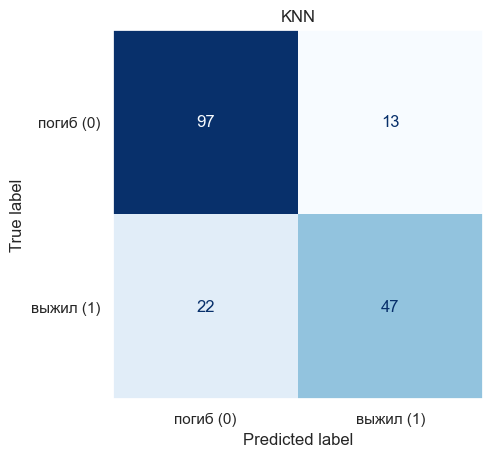

In [36]:
knn_model = knn_searcher.best_estimator_

print("Train: F1 = %.4f, Accuracy = %.4f" % (f1_score(y_train, knn_model.predict(X_train)), accuracy_score(y_train, knn_model.predict(X_train))))
evaluate("KNN", knn_model, knn_searcher.best_score_)
show_confusion("KNN")

Вывод:
- Лучшая комбинация: `k=7` соседей, манхэттенское расстояние (`p=1`), без весов. CV F1 = 0.747. На графике видно, что значения F1 для разных `k` довольно шумные (в основном 0.72–0.75), т.е. сильно зависят от конкретных фолдов, а очень маленькое `k` (2 соседа) явно хуже — слишком локальное решение.
- На тесте F1 = 0.729, Accuracy = 0.805 — порог пройден, но это самый слабый результат среди пяти моделей. Recall самый низкий (0.681, FN = 22).
- ROC-AUC при этом высокий (0.855): KNN неплохо ранжирует пассажиров по вероятности выжить, но при пороге 0.5 (т.е. «большинство из 7 соседей выжили») пропускает много выживших. Это типично для KNN при дисбалансе: среди соседей чаще оказываются погибшие, просто потому что их больше.
- Разрыв train (0.80) и тест (0.73) есть: при `k=7` каждый объект train сам себе один из ближайших соседей, поэтому на train KNN всегда выглядит лучше.

# Часть 12. Нужен ли признак `Title`

Проверяю решение, принятое в части 4. Для каждой модели запускаю тот же случайный поиск, что и выше (те же распределения параметров, то же `n_iter` и тот же `random_state`, т.е. проверяются те же самые наборы гиперпараметров), но без признака `Title`, и сравниваю лучший CV F1. Тест здесь не используется.

In [37]:
no_title = ["Pclass", "Sex", "Embarked"]

searches = {
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), tree_params, False, 50, tree_searcher),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE), rf_params, False, 30, rf_searcher),
    "Gradient Boosting": (GradientBoostingClassifier(random_state=RANDOM_STATE), gb_params, False, 30, gb_searcher),
    "SVM": (SVC(max_iter=100_000), svm_params, True, 40, svm_searcher),
    "KNN": (KNeighborsClassifier(), knn_params, True, 40, knn_searcher),
}

title_check = {}
for name, (model, params, scale, n_iter, searcher) in searches.items():
    searcher_no_title = run_search(model, params, scale, cat_features=no_title, n_iter=n_iter, verbose=False)
    title_check[name] = {"CV F1 без Title": searcher_no_title.best_score_, "CV F1 с Title": searcher.best_score_}

title_check = pd.DataFrame(title_check).T
title_check["разница"] = title_check["CV F1 с Title"] - title_check["CV F1 без Title"]
title_check.loc["среднее"] = title_check.mean()
title_check.round(4)

,CV F1 без Title,CV F1 с Title,разница
Decision Tree,0.7422,0.7612,0.0190
Random Forest,0.7596,0.7686,0.0091
Gradient Boosting,0.7619,0.7731,0.0112
SVM,0.7597,0.7722,0.0126
KNN,0.7422,0.7469,0.0047
среднее,0.7531,0.7644,0.0113


Вывод: `Title` улучшает CV F1 у всех пяти моделей — от +0.005 у KNN до +0.019 у дерева, в среднем на 0.011. Поиск без `Title` перебирал те же самые наборы гиперпараметров, так что разница объясняется только признаком. Прибавка небольшая, но стабильная, и признак осмысленный (он отделяет мальчиков от взрослых мужчин), поэтому оставляю его. Больше всего он помогает дереву: ему проще сделать одно разбиение по `Title_Mr` («взрослый мужчина»), чем отдельно разбивать по полу и возрасту, у которого к тому же 20% пропусков.

# Часть 13. Честное сравнение моделей

Условия для всех моделей одинаковые:
- одни и те же признаки и одни и те же данные: train и test получены одним разбиением в части 2;
- предобработка одна и та же, отличается только `StandardScaler` для SVM и KNN (деревьям он не нужен, а их предсказания от него не изменились бы);
- гиперпараметры всех моделей подобраны случайным поиском по F1 на одних и тех же фолдах `cv`;
- все метрики посчитаны на одном и том же test.

In [38]:
results_df = pd.DataFrame(results).T
results_df["F1 > 0.70"] = results_df["F1"] > 0.70
results_df.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,CV F1,F1 > 0.70
Baseline,0.6145,0.0000,0.0000,0.0000,0.5000,0.0000,False
Decision Tree,0.7877,0.7123,0.7536,0.7324,0.8205,0.7612,True
Random Forest,0.8101,0.7612,0.7391,0.7500,0.8436,0.7686,True
Gradient Boosting,0.8380,0.8333,0.7246,0.7752,0.8351,0.7731,True
SVM,0.8436,0.8254,0.7536,0.7879,0.8586,0.7722,True
KNN,0.8045,0.7833,0.6812,0.7287,0.8546,0.7469,True


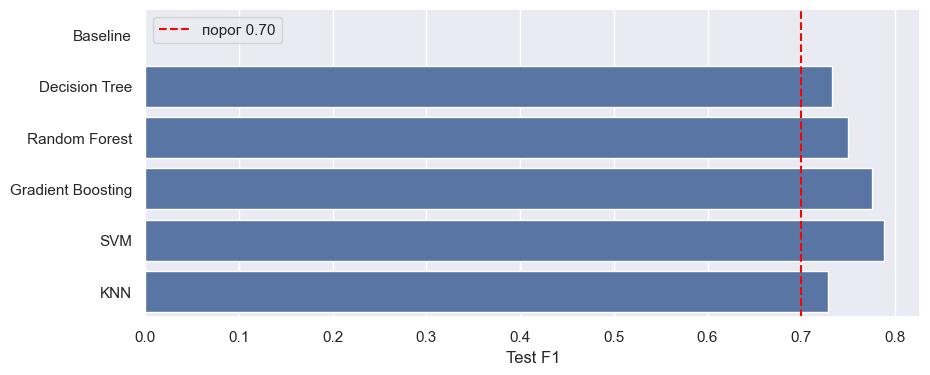

In [39]:
plot = sns.barplot(y=results_df.index, x=results_df["F1"], color="C0")
plot.figure.set_size_inches(10, 4)
plt.axvline(0.70, color="red", linestyle="--", label="порог 0.70")
plt.xlabel("Test F1")
plt.ylabel("")
plt.legend()

,TN,FP,FN,TP
Baseline,110,0,69,0
Decision Tree,89,21,17,52
Random Forest,94,16,18,51
Gradient Boosting,100,10,19,50
SVM,99,11,17,52
KNN,97,13,22,47


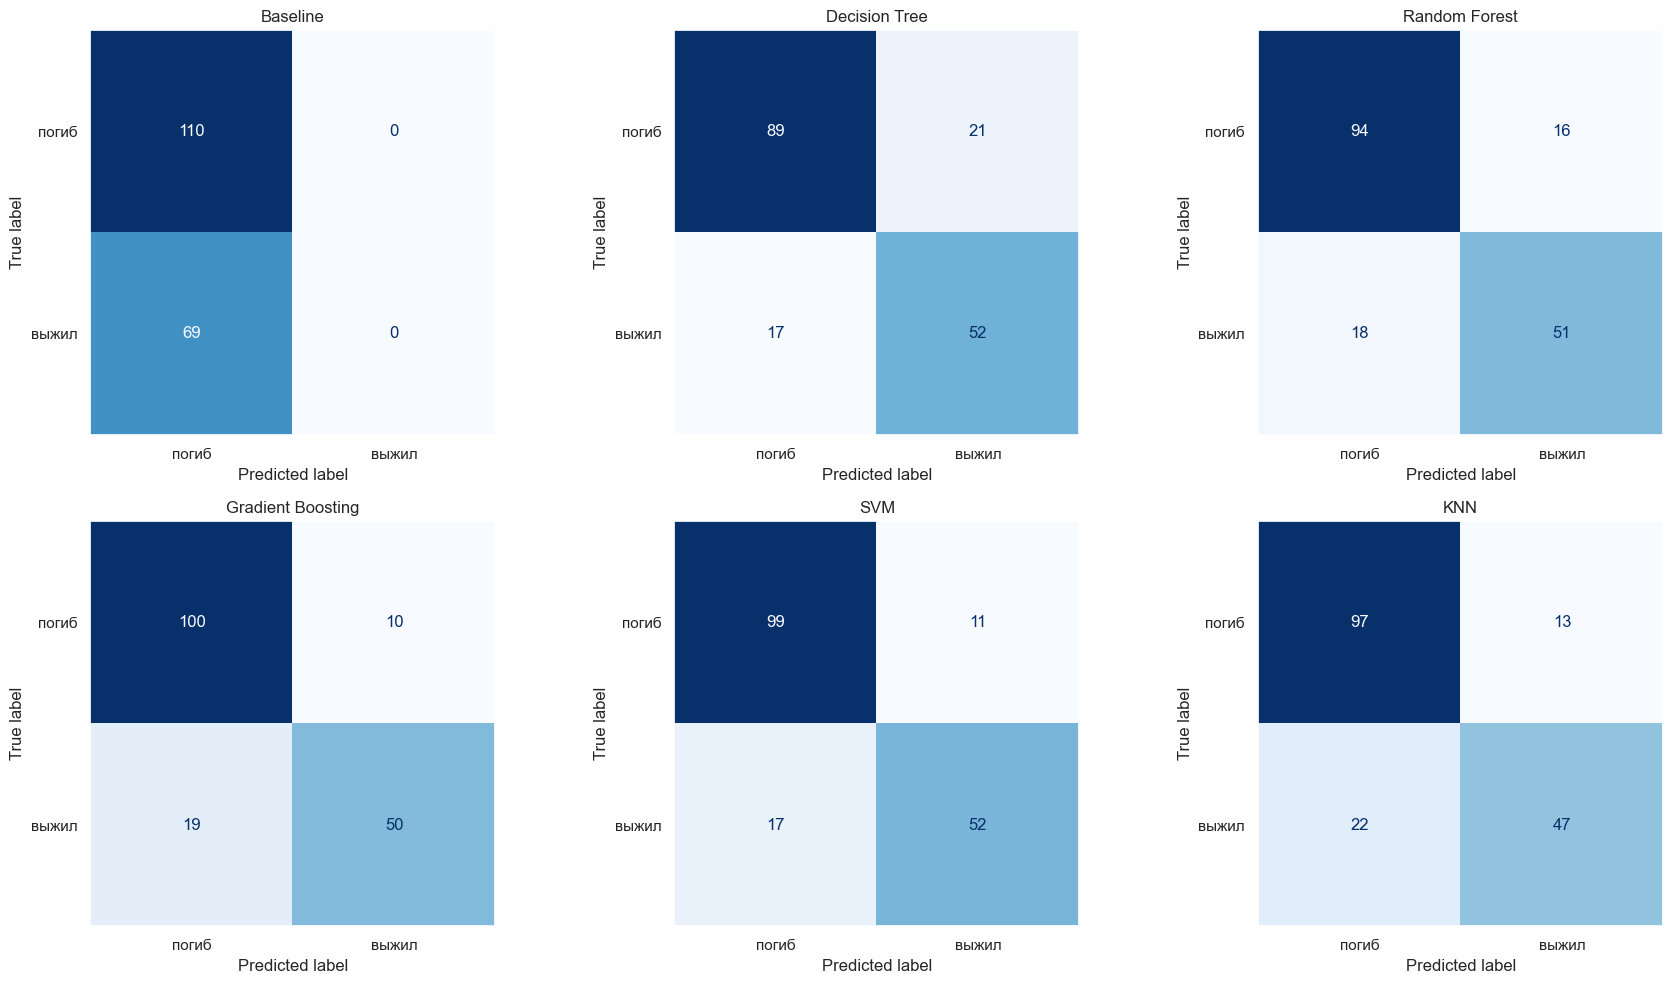

In [40]:
fig, axs = plt.subplots(figsize=(18, 10), nrows=2, ncols=3)
for ax, name in zip(axs.ravel(), predictions):
    cm = confusion_matrix(y_test, predictions[name])
    ConfusionMatrixDisplay(cm, display_labels=["погиб", "выжил"]).plot(cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()

errors_table = {}
for name, y_pred in predictions.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    errors_table[name] = {"TN": tn, "FP": fp, "FN": fn, "TP": tp}
pd.DataFrame(errors_table).T

Выводы:
- **Все пять моделей превзошли baseline и прошли порог F1 > 0.70.** Baseline с Accuracy 0.615 не находит ни одного выжившего (F1 = 0), а все модели находят 68–75% выживших.
- По тесту лучшие — **SVM (F1 = 0.788)** и **Gradient Boosting (0.775)**, дальше Random Forest (0.750), Decision Tree (0.732) и KNN (0.729).
- По кросс-валидации разброс гораздо меньше: от 0.747 (KNN) до 0.773 (GB), а у GB, SVM и RF разница меньше 0.005. Тест маленький (69 выживших), одна-две ошибки сдвигают F1 на 0.01–0.02, поэтому разницу между тремя лучшими моделями нельзя считать значимой.
- **Типы ошибок**: почти у всех моделей FN больше, чем FP, т.е. модели чаще «хоронят» выживших, чем «спасают» погибших. Исключение — дерево с `class_weight="balanced"`: у него FP больше (21), зато Recall выше. Это видно и на том, что у дерева Accuracy ниже, чем у KNN (0.788 против 0.805), а F1 выше (0.732 против 0.729).

Почему модели различаются:
- **Decision Tree** — одна модель с большим разбросом: даже ограниченное дерево переобучается (train 0.87 / test 0.73) и делает «ступенчатые» правила. Поэтому оно хуже ансамблей.
- **Random Forest** усредняет много деревьев и уменьшает разброс, поэтому стабильнее дерева. Но он состоит из глубоких деревьев, и на маленьком датасете всё равно немного переобучается.
- **Gradient Boosting** с неглубокими деревьями и большими листьями хорошо улавливает главные закономерности (пол/обращение → класс → цена/возраст) и их взаимодействие, при этом не переобучается сильно. На табличных данных это обычно сильный выбор.
- **SVM** с RBF-ядром строит гладкую нелинейную границу. Данных мало и признаков немного, после масштабирования пространство признаков «хорошее», и гладкая граница с регуляризацией обобщает лучше всего.
- **KNN** самый простой: он только голосует по ближайшим соседям, все признаки для него одинаково важны (после масштабирования), и он не может «решить», что пол важнее порта посадки. Поэтому шумные признаки (`Embarked`, `Parch`) мешают ему больше, чем остальным моделям.

# Часть 14. Feature importance: сравнение моделей

Получить feature importance напрямую можно у трёх моделей на деревьях (MDI). Сначала сравню их, потом сложу важности one-hot признаков обратно в исходные (например, `Sex_male` + `Sex_female` → `Sex`), потому что one-hot кодирование «разрезает» один признак на несколько.

MDI считается по train и завышает важность непрерывных признаков с большим числом значений, а для SVM и KNN его нет вообще. Поэтому для всех пяти моделей дополнительно посчитаю **permutation importance** по исходным колонкам: перемешиваю значения одного признака в тесте и смотрю, насколько упадёт F1. Это одна и та же величина для любой модели, поэтому модели можно сравнивать. Считаю на тесте, потому что модели уже обучены и зафиксированы, и по этим результатам ничего не выбирается — это только интерпретация.

Text(0.5, 0, 'Importance')

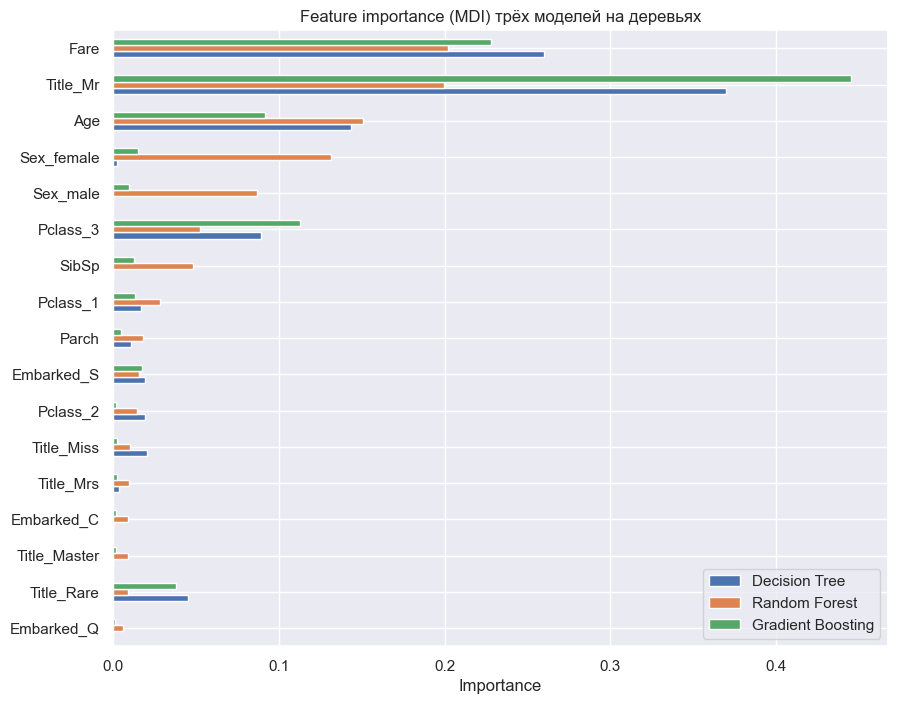

In [41]:
importances = pd.DataFrame({
    "Decision Tree": tree_importances,
    "Random Forest": rf_importances,
    "Gradient Boosting": gb_importances,
}).sort_values("Random Forest")
importances.plot(kind="barh", figsize=(10, 8))
plt.title("Feature importance (MDI) трёх моделей на деревьях")
plt.xlabel("Importance")

In [42]:
def to_original(name):
    for col in categorical:
        if name.startswith(col + "_"):
            return col
    return name

grouped = importances.groupby(importances.index.map(to_original)).sum()
grouped.sort_values("Random Forest", ascending=False).round(3)

,Decision Tree,Random Forest,Gradient Boosting
Title,0.439,0.237,0.490
Sex,0.002,0.218,0.025
Fare,0.260,0.202,0.228
Age,0.144,0.151,0.092
Pclass,0.125,0.095,0.127
SibSp,0.000,0.048,0.013
Embarked,0.019,0.031,0.021
Parch,0.011,0.018,0.005


,Decision Tree,Random Forest,Gradient Boosting,SVM,KNN
Pclass,0.162,0.125,0.155,0.019,0.084
Sex,0.000,0.114,0.083,0.205,0.156
Title,0.280,0.114,0.319,0.102,0.150
Fare,0.098,0.049,0.075,0.017,0.027
Age,0.060,0.026,0.069,0.018,0.022
Embarked,0.023,0.008,0.024,0.015,0.008
SibSp,0.000,-0.005,0.016,0.050,0.038
Parch,0.000,-0.009,-0.007,-0.002,0.011


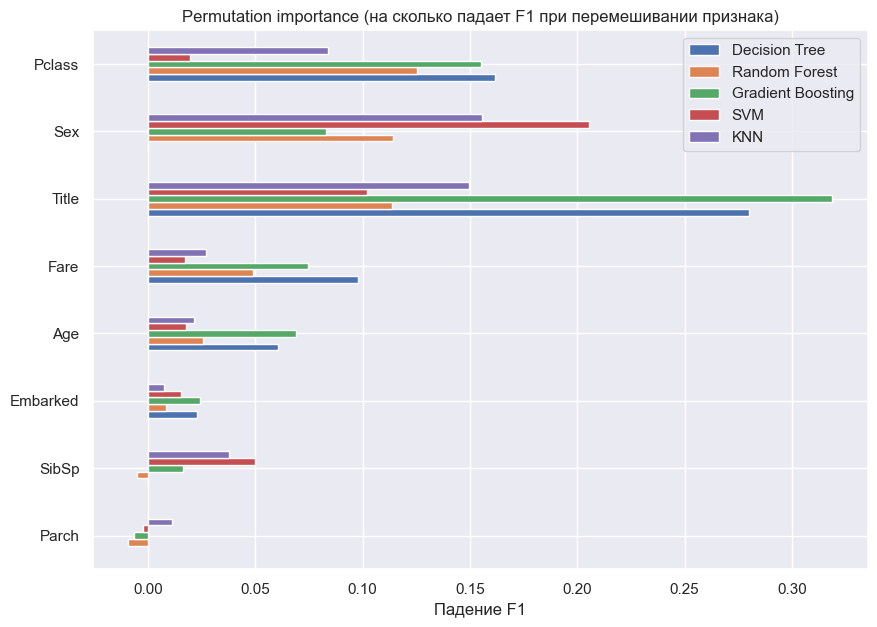

In [43]:
from sklearn.inspection import permutation_importance

models = {"Decision Tree": tree_model, "Random Forest": rf_model, "Gradient Boosting": gb_model, "SVM": svm_model, "KNN": knn_model}
used_columns = numeric + categorical

perm_importances = {}
for name, model in models.items():
    perm = permutation_importance(model, X_test[used_columns], y_test, scoring="f1", n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
    perm_importances[name] = pd.Series(perm.importances_mean, index=used_columns)

perm_importances = pd.DataFrame(perm_importances).sort_values("Random Forest")
perm_importances.plot(kind="barh", figsize=(10, 7))
plt.title("Permutation importance (на сколько падает F1 при перемешивании признака)")
plt.xlabel("Падение F1")

perm_importances.sort_values("Random Forest", ascending=False).round(3)

Выводы:
- **Самые важные признаки у всех моделей — пол/обращение и класс.** По MDI сумма `Title` + `Sex` у всех трёх деревьев — около половины всей важности (0.44 у дерева, 0.46 у леса, 0.52 у бустинга). По permutation importance перемешивание более важного из этой пары (`Title` или `Sex`) снижает F1 на 0.11–0.32, а `Pclass` — на 0.08–0.16 у деревьев и KNN.
- **Деревья (DT и GB) используют `Title` вместо `Sex`**, а лес и SVM/KNN — больше `Sex`. Это два почти взаимозаменяемых признака: если перемешать один, модель частично «спасается» за счёт второго, поэтому их permutation importance по отдельности занижена. Важность пола в целом — это сумма обоих.
- **`Fare` по MDI выглядит одним из главных признаков (0.20–0.26), а по permutation importance — второстепенным (0.02–0.10).** Это и есть смещение MDI: по непрерывному признаку с 226 значениями можно сделать очень много разбиений, и он набирает важность, в том числе на шуме. Плюс `Fare` дублирует класс.
- **`Pclass`, наоборот, по permutation importance важнее, чем по MDI**: по MDI его важность разрезана на три one-hot признака и частично «забрана» ценой билета.
- **`Embarked` и `Parch` почти не важны** ни для одной модели (у `Parch` permutation importance даже около нуля или отрицательная, т.е. это шум).
- **SVM почти не использует `Pclass` (0.02)**, зато сильнее всех опирается на пол (0.21) и использует `SibSp` (0.05). Для гладкой границы SVM класс частично заменяется ценой билета и обращением.

**Сопоставление с EDA.** Важности полностью согласуются с первичным анализом: в EDA сильнее всего выживание различалось по полу (74% против 19%) и классу (65% / 45% / 24%), а возраст был важен в основном для детей — его и выражает `Title` (`Master`). Порт посадки в EDA выглядел связанным с выживанием, но это объяснялось в основном составом классов — и модели его почти не используют. Слабые связи с `SibSp`/`Parch` в EDA тоже подтверждаются: эти признаки на последних местах.

**Можно ли утверждать, что важный для модели признак является причиной выживания?**

Нет. Feature importance показывает только, насколько **модель** опирается на признак при предсказании, т.е. насколько признак статистически связан с выживанием в этих данных. О причинах это ничего не говорит:
1. **Данные наблюдательные.** Никто не менял пол или класс пассажира, чтобы посмотреть, что будет. Мы видим только, что разные группы выживали по-разному.
2. **За признаками стоят настоящие причины, которых нет в данных.** Женщины выживали не из-за пола как такового, а из-за правила «женщины и дети первыми», которое применял экипаж. Пассажиры первого класса — не из-за дорогого билета, а потому что их каюты были ближе к шлюпочной палубе, их раньше предупредили и пустили к шлюпкам. Если бы правило эвакуации было другим, «важность» пола была бы совсем другой.
3. **Признаки подменяют друг друга.** `Title` и `Sex`, `Fare` и `Pclass` — пары сильно связанных признаков. Какой из них окажется «важным», зависит от модели и случайности (дерево выбрало `Title_Mr`, лес — частично `Sex`). У настоящей причины так не было бы.
4. **Важность зависит от модели и способа подсчёта.** MDI и permutation importance дают разный порядок признаков (например, для `Fare` и `Pclass`), разные модели — тоже.
5. Важность ничего не говорит о направлении эффекта и о том, для каких групп он работает.

Чтобы говорить о причинности, нужен эксперимент или специальные методы причинного вывода с явными предположениями. Здесь можно сказать только «признак полезен для предсказания».

# Часть 15. Анализ ошибок лучшей модели

Лучшую модель выбираю по CV F1 (а не по тесту).

Лучшая модель по CV: Gradient Boosting
TN = 100, FP = 10, FN = 19, TP = 50
error_type
OK    150
FN     19
FP     10
Name: count, dtype: int64


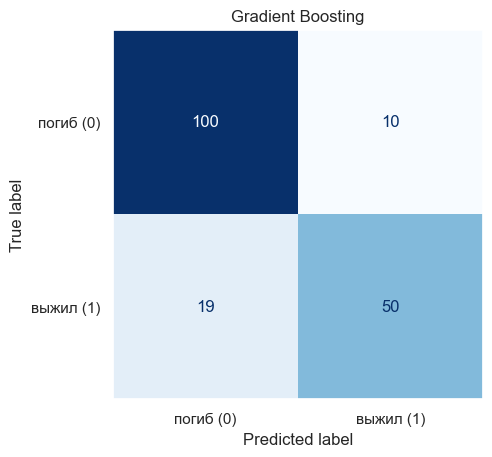

In [44]:
best_name = results_df.drop(index="Baseline")["CV F1"].astype(float).idxmax()
best_model = models[best_name]
print("Лучшая модель по CV:", best_name)

analysis = X_test.copy()
analysis["true"] = y_test
analysis["pred"] = best_model.predict(X_test)
analysis["error"] = analysis["true"] != analysis["pred"]
analysis["error_type"] = np.select(
    [(analysis["true"] == 0) & (analysis["pred"] == 1), (analysis["true"] == 1) & (analysis["pred"] == 0)],
    ["FP", "FN"],
    "OK"
)

show_confusion(best_name)
print(analysis["error_type"].value_counts())

In [45]:
def group_errors(column):
    return analysis.groupby(column).agg(
        n=("error", "size"),
        survived_share=("true", "mean"),
        predicted_share=("pred", "mean"),
        error_rate=("error", "mean"),
        FP=("error_type", lambda s: (s == "FP").sum()),
        FN=("error_type", lambda s: (s == "FN").sum()),
    ).round(3)

for column in ["Sex", "Pclass", ["Sex", "Pclass"], "Title"]:
    print(group_errors(column), "\n")

          n  survived_share  predicted_share  error_rate  FP  FN
Sex                                                             
female   61           0.738             0.77       0.131   5   3
male    118           0.203             0.11       0.178   5  16 

          n  survived_share  predicted_share  error_rate  FP  FN
Pclass                                                          
1        45           0.556            0.533       0.244   5   6
2        34           0.588            0.559       0.088   1   2
3       100           0.240            0.170       0.150   4  11 

                n  survived_share  predicted_share  error_rate  FP  FN
Sex    Pclass                                                         
female 1       15           0.933            1.000       0.067   1   0
       2       18           0.944            1.000       0.056   1   0
       3       28           0.500            0.500       0.214   3   3
male   1       30           0.367            0.300      

Выводы:
- **Чаще всего модель ошибается в сторону FN**: 19 FN против 10 FP. Т.е. главная проблема — выжившие, которых модель «похоронила».
- **Почти все FN — мужчины** (16 из 19, из них 14 — `Mr`). Модель предсказывает выживание только для 11% мужчин в тесте, хотя выжили 20%. Для модели «взрослый мужчина» почти автоматически означает «погиб», и выжившие мужчины для неё — исключения.
- **Сложнее всего — мужчины первого класса**: ошибка 33% (4 FP и 6 FN). Это группа, где выживаемость около 37%, т.е. ближе всего к «монетке», и по имеющимся признакам выживших и погибших мужчин первого класса почти не отличить.
- **Женщины третьего класса** — вторая сложная группа: ошибка 21%, ошибки в обе стороны (3 FP и 3 FN). В этой группе выжила ровно половина, и модель предсказывает выживание тоже для половины, но не угадывает, для какой.
- **Женщины первого и второго класса** — почти без ошибок (6–7%): в train они выживали в 91–97% случаев, и модель всем им говорит «выжила».
- По обращениям: у `Miss` все 5 ошибок — FP (в основном женщины третьего класса, см. ниже), у `Mr` и `Mrs` — в основном FN, у `Master` — 2 FN из 9 (мальчики третьего класса).

In [46]:
show_columns = ["Name", "Sex", "Age", "Pclass", "Title", "SibSp", "Parch", "Fare", "Embarked", "true", "pred"]

print("False Negative (выжил, а модель сказала «погиб»):")
analysis.loc[analysis["error_type"] == "FN", show_columns].head(8)

False Negative (выжил, а модель сказала «погиб»):


,Name,Sex,Age,Pclass,Title,SibSp,Parch,Fare,Embarked,true,pred
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,Mr,0,0,7.2250,C,1,0
279,"Abbott, Mrs. Stanton (Rosa Hunt)",female,35.0,3,Mrs,1,1,20.2500,S,1,0
712,"Taylor, Mr. Elmer Zebley",male,48.0,1,Mr,1,0,52.0000,S,1,0
455,"Jalsevac, Mr. Ivan",male,29.0,3,Mr,0,0,7.8958,C,1,0
489,"Coutts, Master. Eden Leslie ""Neville""",male,9.0,3,Master,1,1,15.9000,S,1,0
165,"Goldsmith, Master. Frank John William ""Frankie""",male,9.0,3,Master,0,2,20.5250,S,1,0
17,"Williams, Mr. Charles Eugene",male,NaN,2,Mr,0,0,13.0000,S,1,0
679,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,1,Mr,0,1,512.3292,C,1,0


In [47]:
print("False Positive (погиб, а модель сказала «выжил»):")
analysis.loc[analysis["error_type"] == "FP", show_columns].head(8)

False Positive (погиб, а модель сказала «выжил»):


,Name,Sex,Age,Pclass,Title,SibSp,Parch,Fare,Embarked,true,pred
698,"Thayer, Mr. John Borland",male,49.0,1,Mr,1,1,110.8833,C,0,1
745,"Crosby, Capt. Edward Gifford",male,70.0,1,Rare,1,1,71.0000,S,0,1
297,"Allison, Miss. Helen Loraine",female,2.0,1,Miss,1,2,151.5500,S,0,1
502,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,Miss,0,0,7.6292,Q,0,1
593,"Bourke, Miss. Mary",female,NaN,3,Miss,0,2,7.7500,Q,0,1
501,"Canavan, Miss. Mary",female,21.0,3,Miss,0,0,7.7500,Q,0,1
245,"Minahan, Dr. William Edward",male,44.0,1,Rare,2,0,90.0000,Q,0,1
826,"Lam, Mr. Len",male,NaN,3,Mr,0,0,56.4958,S,0,1


Разберу несколько ошибок (для части пассажиров посмотрел в исходных данных, с кем они ехали по одному билету):

**False Negative — выжили, а модель сказала «погиб»:**
- **Leeni, Mr. Fahim** и **Jalsevac, Mr. Ivan** — мужчины третьего класса, ехали одни. В train в этой группе выживали только 13.5%, так что по признакам модель права «в среднем», а эти пассажиры — исключения. Причины их спасения (случай, место в момент катастрофы) в данных не отражены.
- **Taylor, Mr. Elmer** и **Cardeza, Mr. Thomas** — мужчины первого класса. Это самая «непредсказуемая» группа: выжили 37%. У Cardeza самый дорогой билет в датасете (512), но модель всё равно считает, что взрослый мужчина скорее погиб.
- **Coutts, Master. Eden** и **Goldsmith, Master. Frank** — мальчики 9 лет из третьего класса. `Master` повышает шансы, но третий класс понижает, и модель склонилась к «погиб». Мальчиков в train всего 31, и для третьего класса примеров ещё меньше.
- **Abbott, Mrs. Stanton** — женщина третьего класса с ребёнком: в этой группе выживает половина, и модель не угадала. При этом её сын, ехавший по тому же билету, погиб.

**False Positive — погибли, а модель сказала «выжил»:**
- **Allison, Miss. Helen Loraine** — девочка 2 лет из первого класса с дорогим билетом. По всем признакам это самый «надёжный» выживший, какой только может быть, но она погибла вместе с матерью (а её брат-младенец и няня спаслись). Такие исключения модель предсказать в принципе не может.
- **Thayer, Mr. John Borland**, **Crosby, Capt. Edward** и **Minahan, Dr. William** — взрослые мужчины первого класса с дорогими билетами. Модель дала им шанс из-за класса и цены билета, но мужчины первого класса чаще погибали. Например, у Thayer выжили жена, сын и горничная, ехавшие по тому же билету, а он сам — нет («женщины и дети первыми»).
- **O'Sullivan, Miss. Bridget**, **Bourke, Miss. Mary**, **Canavan, Miss. Mary** — незамужние женщины третьего класса, севшие в Квинстауне (Ирландия). Для женщин третьего класса шанс 50/50, модель выбрала «выжила» — и ошиблась.
- **Lam, Mr. Len** — мужчина третьего класса, но с ценой билета 56.5, что очень много для третьего класса. Причина — по этому билету ехали 7 человек, и `Fare` — это цена **всего билета**, а не места одного человека. Высокий `Fare` сбил модель. Интересно, что 5 из 7 попутчиков выжили, но сам Лам Лен — нет.

Общая картина: модель хорошо выучила «правила эвакуации» (женщины и дети, первый класс), и ошибается в основном на исключениях из этих правил, особенно в группах, где выживание близко к 50/50. Часть ошибок связана с особенностями данных (`Fare` на группу, а не на человека).

### Не связано ли качество с признаками, которые идентифицируют пассажира?

Проверю это с нескольких сторон:
1. насколько уникальны признаки, которые реально используют модели;
2. что будет, если всё-таки добавить в модель идентификаторы (`PassengerId`, `Ticket`, `Cabin`);
3. насколько подозрительный признак «каюта известна» (`HasCabin`), который я не стал использовать;
4. сколько тестовых пассажиров путешествовали по одному билету с кем-то из train.

In [48]:
print("Уникальных значений в используемых признаках:")
print(X_train[used_columns].nunique())

train_rows = set(map(tuple, X_train[used_columns].fillna(-1).values))
has_copy = np.array([tuple(row) in train_rows for row in X_test[used_columns].fillna(-1).values])
print("\nТестовых пассажиров с точно таким же набором признаков в train: %d из %d" % (has_copy.sum(), len(X_test)))

Уникальных значений в используемых признаках:
Age          85
Fare        226
SibSp         7
Parch         7
Pclass        3
Sex           2
Embarked      3
Title         5
dtype: int64

Тестовых пассажиров с точно таким же набором признаков в train: 35 из 179


In [49]:
id_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric + ["PassengerId"]),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical),
    ("ids", Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="unknown")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), ["Ticket", "Cabin"]),
])

from sklearn.base import clone

leak_check = {}
for name, prep in [("наши признаки", make_preprocess(scale=False)), ("+ PassengerId, Ticket, Cabin", id_preprocess)]:
    model = Pipeline([("prep", prep), ("model", clone(rf_model.named_steps["model"]))])
    res = cross_validate(model, X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
    leak_check[name] = {"Train F1": res["train_score"].mean(), "CV F1": res["test_score"].mean()}
pd.DataFrame(leak_check).T.round(4)

,Train F1,CV F1
наши признаки,0.8794,0.7686
"+ PassengerId, Ticket, Cabin",0.9044,0.7608


In [50]:
X_train_cabin = X_train.assign(HasCabin=X_train["Cabin"].notna().astype(int))

cabin_preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric + ["HasCabin"]),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical),
])
model = Pipeline([("prep", cabin_preprocess), ("model", clone(rf_model.named_steps["model"]))])
print("Random Forest + HasCabin: CV F1 = %.4f (без него %.4f)" % (cross_val_score(model, X_train_cabin, y_train, cv=cv, scoring="f1").mean(), leak_check["наши признаки"]["CV F1"]))

shared_ticket = X_test["Ticket"].isin(X_train["Ticket"])
print("\nТестовых пассажиров, у которых в train есть попутчик с тем же билетом: %d из %d (%.3f)" % (shared_ticket.sum(), len(X_test), shared_ticket.mean()))
print("Ошибка лучшей модели на них: %.3f, на остальных: %.3f" % (analysis.loc[shared_ticket, "error"].mean(), analysis.loc[~shared_ticket, "error"].mean()))

Random Forest + HasCabin: CV F1 = 0.7682 (без него 0.7686)

Тестовых пассажиров, у которых в train есть попутчик с тем же билетом: 67 из 179 (0.374)
Ошибка лучшей модели на них: 0.209, на остальных: 0.134


Выводы:
1. **Используемые признаки пассажира не идентифицируют.** У категориальных признаков от 2 до 5 значений, у `Age` 85, у `Fare` 226. При этом у 35 тестовых пассажиров (20%) есть «двойник» в train с точно таким же набором признаков — это типичные профили (например, мужчина третьего класса с неизвестным возрастом и стандартным билетом за 8.05), а не конкретные люди.
2. **Идентификаторы не помогают, а только добавляют запоминание.** Если добавить в лес `PassengerId`, `Ticket` и `Cabin`, F1 на train вырастает (0.904 против 0.879), а на кросс-валидации падает (0.761 против 0.769). Модель начинает запоминать конкретных пассажиров, и на новых это не работает. Значит, наше качество получено не за счёт таких признаков.
3. **`HasCabin`** с подобранным лесом не даёт прироста на CV (0.768 против 0.769). Т.е. я ничего не теряю, отказавшись от признака, который потенциально содержит информацию, появившуюся после катастрофы.
4. **Попутчики по билету.** У 37% тестовых пассажиров в train есть попутчик с тем же билетом. Если бы модель использовала `Ticket`, она могла бы «подсмотреть» судьбу попутчика (семьи часто спасались или погибали вместе) — это утечка между train и test. Наша модель `Ticket` не использует, и на таких пассажирах ошибается даже чаще (21% против 13%): это в основном семьи, где судьба зависела от того, что происходило с семьёй, а не от индивидуальных признаков. Единственная лазейка — `Fare`: он одинаковый у всех попутчиков по одному билету, поэтому частично работает как идентификатор группы (пример — Lam, Mr. Len). Но по более высокой ошибке на попутчиках видно, что заметного выигрыша модель из этого не извлекает.

Отдельно про «нежелательную информацию»: в этом датасете нет колонок, которые прямо содержат исход (в полной версии Titanic есть номер шлюпки и номер найденного тела — их использовать было бы явной утечкой). Подозрительным был только `Cabin`, и я его не использую. Ещё одна деталь — модель сильно опирается на пол. Для исторической задачи это нормально, это отражает реальное правило эвакуации. Но если бы похожая модель принимала решения о живых людях, использование пола было бы дискриминацией, и такой признак был бы нежелательным уже по этическим причинам.

# Итоги

| Модель | Accuracy | Precision | Recall | F1 | CV F1 |
|---|---|---|---|---|---|
| Baseline (most frequent) | 0.615 | 0.000 | 0.000 | 0.000 | 0.000 |
| Decision Tree | 0.788 | 0.712 | 0.754 | 0.732 | 0.761 |
| Random Forest | 0.810 | 0.761 | 0.739 | 0.750 | 0.769 |
| Gradient Boosting | 0.838 | 0.833 | 0.725 | 0.775 | 0.773 |
| SVM | 0.844 | 0.825 | 0.754 | 0.788 | 0.772 |
| KNN | 0.805 | 0.783 | 0.681 | 0.729 | 0.747 |

- Данные: Titanic (891 пассажир), разбиение 80/20 со стратификацией по `Survived`, `random_state=42`. Признаки: `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked` и `Title` из имени (по кросс-валидации он улучшает F1 у всех пяти моделей). Идентификаторы (`PassengerId`, `Name`, `Ticket`) и подозрительная `Cabin` не используются. Пропуски и кодирование — в `Pipeline`, т.е. только по train.
- Все пять моделей превзошли baseline и прошли порог F1 > 0.70. Лучшая по кросс-валидации — Gradient Boosting (CV F1 = 0.773, на тесте 0.775), лучшая на тесте — SVM (0.788), но разница между GB, SVM и RF в пределах шума.
- Одиночное дерево заметно переобучается; ансамбли и SVM обобщают лучше. Для SVM и KNN масштабирование критично (без него F1 падает до 0.45 и 0.63).
- Главные признаки — пол/обращение и класс, дальше возраст и цена билета. Это совпадает с EDA, но не означает причинной связи.
- Модель чаще пропускает выживших (FN), чем ошибается в обратную сторону; хуже всего предсказывает мужчин первого класса и женщин третьего — группы, где выживание близко к 50/50.
- Качество не связано с признаками-идентификаторами: при их добавлении растёт только качество на train.